In [52]:

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive connected successfully!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected successfully!


In [53]:

import os

# Change this only if your folder has a different name or location
DATA_PATH = "/content/drive/MyDrive/VoltRelay_Datasets"

# Verify folder
if os.path.exists(DATA_PATH):
    print("Dataset folder found!")
    print("Folder location:", DATA_PATH)
else:
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_PATH}"
    )

# List all files
print("\nFiles available:")
for file in sorted(os.listdir(DATA_PATH)):
    print("✔", file)


Dataset folder found!
Folder location: /content/drive/MyDrive/VoltRelay_Datasets

Files available:
✔ batteries.csv
✔ city_daily_context.csv
✔ fleet_partners.csv
✔ riders.csv
✔ station_hourly_status.csv
✔ stations.csv
✔ support_tickets.csv
✔ swap_events.csv


In [54]:

import pandas as pd
import numpy as np
import os
import gc

print("LOADING VOLTRELAY DATASETS")
print("=" * 50)

# Load all eight CSV datasets

swap_events = pd.read_csv(
    f"{DATA_PATH}/swap_events.csv",
    low_memory=False
)

station_status = pd.read_csv(
    f"{DATA_PATH}/station_hourly_status.csv",
    low_memory=False
)

riders = pd.read_csv(
    f"{DATA_PATH}/riders.csv",
    low_memory=False
)

batteries = pd.read_csv(
    f"{DATA_PATH}/batteries.csv",
    low_memory=False
)

tickets = pd.read_csv(
    f"{DATA_PATH}/support_tickets.csv",
    low_memory=False
)

stations = pd.read_csv(
    f"{DATA_PATH}/stations.csv",
    low_memory=False
)

city_context = pd.read_csv(
    f"{DATA_PATH}/city_daily_context.csv",
    low_memory=False
)

fleet_partners = pd.read_csv(
    f"{DATA_PATH}/fleet_partners.csv",
    low_memory=False
)

# Convert date columns

swap_events["event_ts"] = pd.to_datetime(
    swap_events["event_ts"], errors="coerce"
)

station_status["hour_start"] = pd.to_datetime(
    station_status["hour_start"], errors="coerce"
)

riders["signup_date"] = pd.to_datetime(
    riders["signup_date"], errors="coerce"
)

tickets["created_ts"] = pd.to_datetime(
    tickets["created_ts"], errors="coerce"
)

stations["commissioned_date"] = pd.to_datetime(
    stations["commissioned_date"], errors="coerce"
)

city_context["date"] = pd.to_datetime(
    city_context["date"], errors="coerce"
)

print("\nALL EIGHT DATASETS LOADED SUCCESSFULLY!")


LOADING VOLTRELAY DATASETS

ALL EIGHT DATASETS LOADED SUCCESSFULLY!


In [55]:

# Store all datasets in one dictionary
datasets = {
    "Swap Events": swap_events,
    "Station Hourly Status": station_status,
    "Riders": riders,
    "Batteries": batteries,
    "Support Tickets": tickets,
    "Stations": stations,
    "City Daily Context": city_context,
    "Fleet Partners": fleet_partners
}

# Display dataset dimensions
print("DATASET DIMENSIONS")
print("=" * 70)

for name, df in datasets.items():
    print(f"{name:25} | Rows: {len(df):>10,} | Columns: {len(df.columns):>3}")

print("\nDATASET CHECK COMPLETED!")


DATASET DIMENSIONS
Swap Events               | Rows:  3,877,013 | Columns:  22
Station Hourly Status     | Rows:  1,487,712 | Columns:  14
Riders                    | Rows:     20,000 | Columns:  12
Batteries                 | Rows:      6,500 | Columns:  13
Support Tickets           | Rows:     44,000 | Columns:  12
Stations                  | Rows:        152 | Columns:  22
City Daily Context        | Rows:      3,282 | Columns:  12
Fleet Partners            | Rows:         12 | Columns:  12

DATASET CHECK COMPLETED!


In [56]:

for name, df in datasets.items():

    print("\n" + "=" * 80)
    print("DATASET:", name)
    print("=" * 80)

    print("\nColumn Names:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if len(missing) > 0:
        print(missing.sort_values(ascending=False))
    else:
        print("No missing values found.")

    print("\nFirst 5 Records:")
    display(df.head())



DATASET: Swap Events

Column Names:
['event_id', 'rider_id', 'station_id', 'event_ts', 'event_type', 'attempt_seq', 'queue_wait_sec', 'battery_in_id', 'battery_out_id', 'soc_in_pct', 'soh_in_pct', 'soc_out_pct', 'soh_out_pct', 'km_since_last_swap', 'tariff_code', 'list_price_inr', 'discount_inr', 'amount_charged_inr', 'payment_mode', 'energy_to_recharge_kwh', 'station_firmware', 'sync_mode']

Data Types:
event_id                          object
rider_id                          object
station_id                        object
event_ts                  datetime64[ns]
event_type                        object
attempt_seq                        int64
queue_wait_sec                     int64
battery_in_id                     object
battery_out_id                    object
soc_in_pct                       float64
soh_in_pct                       float64
soc_out_pct                      float64
soh_out_pct                      float64
km_since_last_swap               float64
tariff_code      

,event_id,rider_id,station_id,event_ts,event_type,attempt_seq,queue_wait_sec,battery_in_id,battery_out_id,soc_in_pct,...,soh_out_pct,km_since_last_swap,tariff_code,list_price_inr,discount_inr,amount_charged_inr,payment_mode,energy_to_recharge_kwh,station_firmware,sync_mode
0,SW-000000001,RD-1000003,STN-MUM-115,2024-01-01 11:10:56,swap_completed,1,88,BAT-2W-103542,BAT-2W-102547,15.0,...,98.9,80.4,PARTNER,60.0,6.0,54.0,partner_invoice,2.035,v3.2.1,realtime
1,SW-000000002,RD-1000004,STN-HYD-070,2024-01-01 17:13:06,swap_completed,1,148,BAT-2W-105296,BAT-2W-101923,8.3,...,98.2,66.1,PARTNER,60.0,9.0,51.0,partner_invoice,2.157,v3.2.0,realtime
2,SW-000000003,RD-1000005,STN-DEL-046,2024-01-01 20:15:14,swap_completed,1,307,BAT-2W-104732,BAT-2W-102492,11.5,...,99.1,66.6,STD,60.0,0.0,60.0,partner_invoice,2.039,v3.2.0,realtime
3,SW-000000004,RD-1000006,STN-JAI-135,2024-01-01 20:26:07,swap_completed,1,399,BAT-2W-103839,BAT-2W-103267,7.9,...,98.2,65.4,STD,60.0,0.0,60.0,partner_invoice,2.194,v3.2.0,realtime
4,SW-000000005,RD-1000012,STN-PUN-100,2024-01-01 21:13:07,swap_completed,1,201,BAT-2W-104056,BAT-2W-106218,10.5,...,99.9,73.8,STD,60.0,0.0,60.0,partner_invoice,1.971,v3.2.1,realtime



DATASET: Station Hourly Status

Column Names:
['station_id', 'hour_start', 'charged_2w_avg', 'charged_2w_min', 'charged_3w_min', 'packs_charging', 'packs_quarantined', 'chargers_online', 'ambient_temp_c', 'cabinet_temp_c', 'avg_charge_minutes', 'outage_minutes', 'grid_kwh', 'telemetry_status']

Data Types:
station_id                    object
hour_start            datetime64[ns]
charged_2w_avg               float64
charged_2w_min               float64
charged_3w_min               float64
packs_charging               float64
packs_quarantined            float64
chargers_online                int64
ambient_temp_c               float64
cabinet_temp_c               float64
avg_charge_minutes           float64
outage_minutes                 int64
grid_kwh                     float64
telemetry_status              object
dtype: object

Missing Values:
charged_3w_min        821808
charged_2w_avg          9384
charged_2w_min          9384
packs_charging          9384
packs_quarantined       93

,station_id,hour_start,charged_2w_avg,charged_2w_min,charged_3w_min,packs_charging,packs_quarantined,chargers_online,ambient_temp_c,cabinet_temp_c,avg_charge_minutes,outage_minutes,grid_kwh,telemetry_status
0,STN-BLR-001,2024-01-01 00:00:00,6.29,6.0,4.0,1.0,0.0,18,8.2,13.5,92.6,0,1.86,ok
1,STN-BLR-001,2024-01-01 01:00:00,8.10,8.0,4.0,8.0,0.0,18,8.2,11.5,88.0,0,13.96,ok
2,STN-BLR-001,2024-01-01 02:00:00,10.56,8.0,4.0,5.0,0.0,18,8.2,12.9,80.2,0,8.27,ok
3,STN-BLR-001,2024-01-01 03:00:00,7.44,6.0,3.0,5.0,0.0,18,8.2,13.2,86.7,0,8.38,ok
4,STN-BLR-001,2024-01-01 04:00:00,9.18,7.0,3.0,3.0,0.0,18,8.2,14.0,83.9,0,4.28,ok



DATASET: Riders

Column Names:
['rider_id', 'partner_id', 'vehicle_class', 'vehicle_model', 'home_zone', 'signup_date', 'signup_channel', 'plan_type', 'declared_shift', 'age_band', 'kyc_verified', 'home_city']

Data Types:
rider_id                  object
partner_id                object
vehicle_class             object
vehicle_model             object
home_zone                 object
signup_date       datetime64[ns]
signup_channel            object
plan_type                 object
declared_shift            object
age_band                  object
kyc_verified                bool
home_city                 object
dtype: object

Missing Values:
partner_id        7628
declared_shift    3662
age_band          1547
dtype: int64

First 5 Records:


,rider_id,partner_id,vehicle_class,vehicle_model,home_zone,signup_date,signup_channel,plan_type,declared_shift,age_band,kyc_verified,home_city
0,RD-1000000,FP-04,3W,Kranti Cargo3,DEL-Noida,2023-03-08,field_agent,partner_billed,night,45+,True,Delhi NCR
1,RD-1000001,FP-05,2W,Volt Cub,MUM-Thane,2023-03-08,partner_onboarding,partner_billed,mixed,35-44,True,Mumbai
2,RD-1000002,FP-06,2W,Torq X1,HYD-West,2023-03-08,partner_onboarding,partner_billed,evening,25-34,False,Hyderabad
3,RD-1000003,FP-01,2W,Zipp E2,MUM-Navi Mumbai,2023-03-08,partner_onboarding,partner_billed,evening,25-34,True,Mumbai
4,RD-1000004,FP-02,2W,Zipp E2,HYD-Hitech City,2023-03-08,partner_onboarding,partner_billed,night,NaN,True,Hyderabad


... (6 outputs left out)


DATASET: City Daily Context

Column Names:
['city', 'date', 'max_temp_c', 'min_temp_c', 'rainfall_mm', 'heat_alert', 'flood_disruption', 'festival_or_event', 'is_public_holiday', 'grid_outage_hours', 'competitor_promo_active', 'ecommerce_sale_event']

Data Types:
city                               object
date                       datetime64[ns]
max_temp_c                        float64
min_temp_c                        float64
rainfall_mm                       float64
heat_alert                           bool
flood_disruption                     bool
festival_or_event                  object
is_public_holiday                    bool
grid_outage_hours                 float64
competitor_promo_active              bool
ecommerce_sale_event                 bool
dtype: object

Missing Values:
festival_or_event    3172
dtype: int64

First 5 Records:


,city,date,max_temp_c,min_temp_c,rainfall_mm,heat_alert,flood_disruption,festival_or_event,is_public_holiday,grid_outage_hours,competitor_promo_active,ecommerce_sale_event
0,Bengaluru,2024-01-01,16.7,6.7,0.0,False,False,NaN,False,0.0,False,False
1,Bengaluru,2024-01-02,17.3,4.6,1.8,False,False,NaN,False,0.2,False,False
2,Bengaluru,2024-01-03,13.9,6.9,0.7,False,False,NaN,False,0.0,False,False
3,Bengaluru,2024-01-04,17.9,4.0,2.2,False,False,NaN,False,0.1,False,False
4,Bengaluru,2024-01-05,16.0,7.8,2.0,False,False,NaN,False,0.0,False,False



DATASET: Fleet Partners

Column Names:
['partner_id', 'partner_name', 'partner_segment', 'vehicle_class', 'contract_type', 'contract_start_date', 'discount_pct', 'amendment_date', 'discount_pct_after_amendment', 'peak_surcharge_billable', 'payment_terms_days', 'cities_active']

Data Types:
partner_id                       object
partner_name                     object
partner_segment                  object
vehicle_class                    object
contract_type                    object
contract_start_date              object
discount_pct                    float64
amendment_date                   object
discount_pct_after_amendment    float64
peak_surcharge_billable          object
payment_terms_days                int64
cities_active                    object
dtype: object

Missing Values:
amendment_date                  11
discount_pct_after_amendment    11
dtype: int64

First 5 Records:


,partner_id,partner_name,partner_segment,vehicle_class,contract_type,contract_start_date,discount_pct,amendment_date,discount_pct_after_amendment,peak_surcharge_billable,payment_terms_days,cities_active
0,FP-01,FeastFly,food_delivery,2W,volume_tiered,2023-04-01,10.0,NaN,NaN,Y,30,BLR|DEL|HYD|PUN|MUM|JAI
1,FP-02,ParcelNest,ecom_logistics,2W,pay_per_swap,2023-07-01,15.0,NaN,NaN,Y,30,BLR|DEL|HYD|MUM
2,FP-03,ZipDrop,quick_commerce,2W,volume_tiered,2023-06-01,12.0,2024-11-01,28.0,N,45,BLR|DEL|HYD|PUN|MUM|JAI
3,FP-04,CargoTuk,cargo_3w,3W,pay_per_swap,2023-09-01,8.0,NaN,NaN,Y,30,DEL|HYD|JAI
4,FP-05,Swiggle Go,food_delivery,2W,volume_tiered,2023-05-01,11.0,NaN,NaN,N,30,BLR|PUN|MUM


In [57]:

print("DATA QUALITY INITIAL CHECK")
print("=" * 70)

for name, df in datasets.items():

    print(f"\n{name}")

    print("Total rows:", f"{len(df):,}")
    print("Duplicate complete rows:", f"{df.duplicated().sum():,}")

    memory = df.memory_usage(deep=True).sum() / (1024 ** 2)

    print("Memory usage:", round(memory, 2), "MB")

print("\nINITIAL DATA QUALITY CHECK COMPLETED!")


DATA QUALITY INITIAL CHECK

Swap Events
Total rows: 3,877,013
Duplicate complete rows: 0
Memory usage: 2561.94 MB

Station Hourly Status
Total rows: 1,487,712
Duplicate complete rows: 0
Memory usage: 293.89 MB

Riders
Total rows: 20,000
Duplicate complete rows: 0
Memory usage: 10.81 MB

Batteries
Total rows: 6,500
Duplicate complete rows: 0
Memory usage: 3.18 MB

Support Tickets
Total rows: 44,000
Duplicate complete rows: 0
Memory usage: 23.99 MB

Stations
Total rows: 152
Duplicate complete rows: 0
Memory usage: 0.1 MB

City Daily Context
Total rows: 3,282
Duplicate complete rows: 0
Memory usage: 0.42 MB

Fleet Partners
Total rows: 12
Duplicate complete rows: 0
Memory usage: 0.01 MB

INITIAL DATA QUALITY CHECK COMPLETED!


In [58]:

print("SWAP EVENT OUTCOME ANALYSIS")
print("=" * 50)

outcomes = swap_events["event_type"].value_counts()

display(outcomes.to_frame(name="Number of Events"))

print("\nPercentage Distribution:")

display(
    (swap_events["event_type"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame(name="Percentage")
)


SWAP EVENT OUTCOME ANALYSIS


,Number of Events
event_type,
swap_completed,3645809
failed_no_charged_battery,134389
abandoned_queue,68533
cancelled_by_rider,16712
failed_system_error,11570



Percentage Distribution:


,Percentage
event_type,
swap_completed,94.04
failed_no_charged_battery,3.47
abandoned_queue,1.77
cancelled_by_rider,0.43
failed_system_error,0.30


In [59]:

print("SWAP EVENT DATE RANGE")

print("First event:",
      swap_events["event_ts"].min())

print("Last event:",
      swap_events["event_ts"].max())

print("\nNumber of unique riders:",
      swap_events["rider_id"].nunique())

print("Number of unique stations:",
      swap_events["station_id"].nunique())

print("Number of unique batteries:",
      pd.concat([
          swap_events["battery_in_id"],
          swap_events["battery_out_id"]
      ]).nunique())


SWAP EVENT DATE RANGE
First event: 2024-01-01 00:00:33
Last event: 2025-06-30 23:59:23

Number of unique riders: 19950
Number of unique stations: 152
Number of unique batteries: 6500


In [60]:

print("=" * 65)
print("STEP 9 - DATA QUALITY INVESTIGATION")
print("=" * 65)

# 1. Check primary key duplicates
print("\n1. PRIMARY KEY CHECK")

for name, df, key in [
    ("Swap Events", swap_events, "event_id"),
    ("Riders", riders, "rider_id"),
    ("Batteries", batteries, "battery_id"),
    ("Support Tickets", tickets, "ticket_id"),
    ("Stations", stations, "station_id"),
    ("Fleet Partners", fleet_partners, "partner_id")
]:
    print(name, "duplicate keys:", df[key].duplicated().sum())

# 2. Check test stations
print("\n2. TEST STATION CHECK")

test_stations = stations[
    stations["station_id"].str.startswith("STN-TST", na=False)
]

print("Test stations found:", len(test_stations))
display(test_stations[["station_id", "city", "location_type"]])

# 3. Check firmware timestamp issue
print("\n3. FIRMWARE TIMESTAMP CHECK")

firmware_mask = (
    swap_events["station_firmware"].eq("v3.2.0") &
    swap_events["event_ts"].ge("2025-03-10") &
    swap_events["event_ts"].lt("2025-04-15")
)

print("Potentially affected events:", firmware_mask.sum())

# 4. Check invalid distance readings
print("\n4. DISTANCE OUTLIER CHECK")

distance = swap_events["km_since_last_swap"]

print("Missing distance:", distance.isna().sum())
print("Negative distance:", (distance < 0).sum())
print("Distance above 300 km:", (distance > 300).sum())
print("Maximum distance:", distance.max())

# 5. Check charge-level anomalies
print("\n5. CHARGE LEVEL CHECK")

for col in ["soc_in_pct", "soc_out_pct"]:
    print("\n", col)
    print("Below 0:", (swap_events[col] < 0).sum())
    print("Above 100:", (swap_events[col] > 100).sum())

# 6. Check near-duplicate candidates
print("\n6. OFFLINE SYNC NEAR-DUPLICATE CHECK")

offline = swap_events[
    swap_events["sync_mode"].eq("offline_batch")
]

duplicate_keys = [
    "rider_id", "station_id",
    "battery_in_id", "battery_out_id"
]

offline_sorted = offline.sort_values(
    duplicate_keys + ["event_ts"]
)

time_gap = (
    offline_sorted.groupby(
        duplicate_keys,
        dropna=False
    )["event_ts"].diff()
)

near_duplicate_mask = (
    time_gap.ge(pd.Timedelta(seconds=0)) &
    time_gap.le(pd.Timedelta(minutes=2))
)

print("Offline batch events:", len(offline))
print("Potential near-duplicate events:", near_duplicate_mask.sum())

# 7. Check broken foreign key relationships
print("\n7. FOREIGN KEY CHECK")

print(
    "Events with unknown riders:",
    (~swap_events["rider_id"].isin(riders["rider_id"])).sum()
)

print(
    "Events with unknown stations:",
    (~swap_events["station_id"].isin(stations["station_id"])).sum()
)

print(
    "Tickets with unknown riders:",
    (~tickets["rider_id"].isin(riders["rider_id"])).sum()
)

print("\nSTEP 9 INVESTIGATION COMPLETED!")


STEP 9 - DATA QUALITY INVESTIGATION

1. PRIMARY KEY CHECK
Swap Events duplicate keys: 0
Riders duplicate keys: 0
Batteries duplicate keys: 0
Support Tickets duplicate keys: 0
Stations duplicate keys: 0
Fleet Partners duplicate keys: 0

2. TEST STATION CHECK
Test stations found: 2


,station_id,city,location_type
150,STN-TST-01,Bengaluru,commercial_hub
151,STN-TST-02,Bengaluru,commercial_hub



3. FIRMWARE TIMESTAMP CHECK
Potentially affected events: 139490

4. DISTANCE OUTLIER CHECK
Missing distance: 28282
Negative distance: 7814
Distance above 300 km: 7712
Maximum distance: 420.0

5. CHARGE LEVEL CHECK

 soc_in_pct
Below 0: 0
Above 100: 0

 soc_out_pct
Below 0: 0
Above 100: 3698

6. OFFLINE SYNC NEAR-DUPLICATE CHECK
Offline batch events: 591114
Potential near-duplicate events: 0

7. FOREIGN KEY CHECK
Events with unknown riders: 0
Events with unknown stations: 0
Tickets with unknown riders: 0

STEP 9 INVESTIGATION COMPLETED!


In [61]:

print("=" * 65)
print("STEP 10 - FIRMWARE TIMESTAMP CORRECTION")
print("=" * 65)

# Preserve the original timestamp and create a corrected column
swap_events["event_ts_corrected"] = swap_events["event_ts"]

# Identify events affected by the firmware issue
firmware_mask = (
    swap_events["station_firmware"].eq("v3.2.0") &
    swap_events["event_ts"].ge("2025-03-10") &
    swap_events["event_ts"].lt("2025-04-15")
)

# Correct affected timestamps by adding 5 hours and 30 minutes
swap_events.loc[firmware_mask, "event_ts_corrected"] = (
    swap_events.loc[firmware_mask, "event_ts"]
    + pd.Timedelta(hours=5, minutes=30)
)

# Display correction summary
print("Total events:", len(swap_events))
print("Affected events:", firmware_mask.sum())
print("Corrected events:",
      (swap_events["event_ts_corrected"] != swap_events["event_ts"]).sum())

# Display a few corrected examples
print("\nSAMPLE TIMESTAMP CORRECTIONS")

display(
    swap_events.loc[
        firmware_mask,
        ["station_firmware", "event_ts", "event_ts_corrected"]
    ].head(10)
)

print("\nSTEP 10 COMPLETED!")


STEP 10 - FIRMWARE TIMESTAMP CORRECTION
Total events: 3877013
Affected events: 139490
Corrected events: 139490

SAMPLE TIMESTAMP CORRECTIONS


,station_firmware,event_ts,event_ts_corrected
2671233,v3.2.0,2025-03-10 12:53:23,2025-03-10 18:23:23
2671234,v3.2.0,2025-03-10 08:04:09,2025-03-10 13:34:09
2671235,v3.2.0,2025-03-10 11:15:21,2025-03-10 16:45:21
2671238,v3.2.0,2025-03-10 13:59:42,2025-03-10 19:29:42
2671239,v3.2.0,2025-03-10 12:47:19,2025-03-10 18:17:19
2671245,v3.2.0,2025-03-10 14:35:06,2025-03-10 20:05:06
2671246,v3.2.0,2025-03-10 13:49:49,2025-03-10 19:19:49
2671247,v3.2.0,2025-03-10 14:58:45,2025-03-10 20:28:45
2671251,v3.2.0,2025-03-10 14:00:34,2025-03-10 19:30:34
2671269,v3.2.0,2025-03-10 06:25:13,2025-03-10 11:55:13



STEP 10 COMPLETED!


In [62]:

print("=" * 65)
print("STEP 11 - INVESTIGATE DISTANCE AND SOC ANOMALIES")
print("=" * 65)

# 1. DISTANCE DISTRIBUTION
distance = swap_events["km_since_last_swap"]

print("\n1. DISTANCE DISTRIBUTION")

print("Total records:", len(distance))
print("Missing:", distance.isna().sum())
print("Negative:", (distance < 0).sum())
print("Zero:", (distance == 0).sum())
print("Above 300 km:", (distance > 300).sum())

# Examine the distribution of non-negative distances
valid_distance = distance[distance >= 0]

print("\nNon-negative distance statistics:")
display(valid_distance.describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
).to_frame("km_since_last_swap"))

# 2. EXAMINE VERY LARGE DISTANCE VALUES
print("\n2. SAMPLE DISTANCE VALUES ABOVE 300 KM")

display(
    swap_events.loc[
        distance > 300,
        ["event_id", "event_type", "km_since_last_swap",
         "rider_id", "station_id"]
    ].head(15)
)

# 3. EXAMINE NEGATIVE DISTANCE VALUES
print("\n3. SAMPLE NEGATIVE DISTANCE VALUES")

display(
    swap_events.loc[
        distance < 0,
        ["event_id", "event_type", "km_since_last_swap",
         "rider_id", "station_id"]
    ].head(15)
)

# 4. SOC ANOMALIES
print("\n4. SOC ABOVE 100%")

soc_mask = swap_events["soc_out_pct"] > 100

print("Total SOC outliers:", soc_mask.sum())

display(
    swap_events.loc[
        soc_mask,
        ["event_id", "event_type", "soc_out_pct",
         "soh_out_pct", "station_id", "station_firmware"]
    ].head(15)
)

# 5. SOC OUTLIERS BY EVENT TYPE
print("\n5. SOC OUTLIERS BY EVENT TYPE")

display(
    swap_events.loc[soc_mask]
    .groupby("event_type")
    .size()
    .to_frame("outlier_count")
)

# 6. SUMMARY
print("\n6. INVESTIGATION SUMMARY")

print("Negative distance:", (distance < 0).sum())
print("Distance above 300 km:", (distance > 300).sum())
print("SOC above 100%:", soc_mask.sum())

print("\nSTEP 11 INVESTIGATION COMPLETED!")


STEP 11 - INVESTIGATE DISTANCE AND SOC ANOMALIES

1. DISTANCE DISTRIBUTION
Total records: 3877013
Missing: 28282
Negative: 7814
Zero: 0
Above 300 km: 7712

Non-negative distance statistics:


,km_since_last_swap
count,3.840917e+06
mean,6.218271e+01
std,2.019654e+01
min,2.210000e+01
25%,5.190000e+01
50%,6.000000e+01
75%,6.900000e+01
90%,8.060000e+01
95%,9.110000e+01
99%,1.070000e+02



2. SAMPLE DISTANCE VALUES ABOVE 300 KM


,event_id,event_type,km_since_last_swap,rider_id,station_id
350,SW-000000351,swap_completed,367.9,RD-1000692,STN-HYD-076
635,SW-000000636,swap_completed,335.7,RD-1001276,STN-JAI-141
1927,SW-000001928,swap_completed,401.7,RD-1000097,STN-PUN-096
2529,SW-000002530,swap_completed,339.6,RD-1000731,STN-PUN-096
2616,SW-000002617,swap_completed,351.4,RD-1000820,STN-HYD-075
3272,SW-000003273,swap_completed,395.9,RD-1001523,STN-DEL-045
4565,SW-000004566,swap_completed,380.5,RD-1002974,STN-MUM-112
4569,SW-000004570,swap_completed,340.5,RD-1002981,STN-JAI-136
5037,SW-000005038,swap_completed,376.1,RD-1003490,STN-JAI-139
5194,SW-000005195,swap_completed,351.7,RD-1000038,STN-MUM-120



3. SAMPLE NEGATIVE DISTANCE VALUES


,event_id,event_type,km_since_last_swap,rider_id,station_id
417,SW-000000418,swap_completed,-3.2,RD-1000807,STN-PUN-093
453,SW-000000454,swap_completed,-19.1,RD-1000891,STN-JAI-141
496,SW-000000497,swap_completed,-10.1,RD-1000979,STN-HYD-076
673,SW-000000674,swap_completed,-3.1,RD-1001356,STN-BLR-006
823,SW-000000824,swap_completed,-3.6,RD-1001637,STN-PUN-099
3405,SW-000003406,swap_completed,-18.9,RD-1001664,STN-BLR-014
3511,SW-000003512,swap_completed,-18.3,RD-1001784,STN-HYD-070
4153,SW-000004154,swap_completed,-15.6,RD-1002526,STN-HYD-068
4513,SW-000004514,swap_completed,-18.7,RD-1002906,STN-TST-01
5110,SW-000005111,swap_completed,-3.1,RD-1003573,STN-HYD-075



4. SOC ABOVE 100%
Total SOC outliers: 3698


,event_id,event_type,soc_out_pct,soh_out_pct,station_id,station_firmware
2313,SW-000002314,swap_completed,101.0,98.7,STN-HYD-068,v3.2.0
5739,SW-000005740,swap_completed,102.9,98.4,STN-PUN-093,v3.2.1
5767,SW-000005768,swap_completed,103.0,99.5,STN-DEL-048,v3.2.0
6493,SW-000006494,swap_completed,102.5,99.0,STN-HYD-067,v3.2.1
6581,SW-000006582,swap_completed,102.9,98.9,STN-BLR-019,v3.2.1
11055,SW-000011056,swap_completed,102.7,99.1,STN-PUN-096,v3.2.1
11727,SW-000011728,swap_completed,101.0,100.1,STN-DEL-046,v3.2.0
12345,SW-000012346,swap_completed,100.9,100.4,STN-PUN-093,v3.2.1
12391,SW-000012392,swap_completed,101.7,99.4,STN-MUM-119,v3.2.1
12807,SW-000012808,swap_completed,101.2,99.4,STN-HYD-063,v3.2.1



5. SOC OUTLIERS BY EVENT TYPE


,outlier_count
event_type,
swap_completed,3698



6. INVESTIGATION SUMMARY
Negative distance: 7814
Distance above 300 km: 7712
SOC above 100%: 3698

STEP 11 INVESTIGATION COMPLETED!


In [63]:

print("=" * 65)
print("STEP 12 - CREATE DATA QUALITY FLAGS")
print("=" * 65)

# 1. Distance quality flags
swap_events["distance_negative_flag"] = (
    swap_events["km_since_last_swap"] < 0
)

swap_events["distance_above_300_flag"] = (
    swap_events["km_since_last_swap"] > 300
)

swap_events["distance_missing_flag"] = (
    swap_events["km_since_last_swap"].isna()
)

# Flag readings needing review
swap_events["distance_review_flag"] = (
    swap_events["distance_negative_flag"] |
    swap_events["distance_above_300_flag"]
)

# A provisional distance column for analysis.
# Values outside 0-300 km are set to missing in this separate column.
# Original km_since_last_swap remains unchanged.
swap_events["distance_analysis_km"] = (
    swap_events["km_since_last_swap"].where(
        swap_events["km_since_last_swap"].between(0, 300)
    )
)

# 2. SOC quality flags
swap_events["soc_out_above_100_flag"] = (
    swap_events["soc_out_pct"] > 100
)

swap_events["soc_out_missing_flag"] = (
    swap_events["soc_out_pct"].isna()
)

# Separate SOC column for analysis; no clipping
swap_events["soc_out_analysis_pct"] = (
    swap_events["soc_out_pct"].where(
        swap_events["soc_out_pct"].between(0, 100)
    )
)

# 3. Display summary
print("\n1. DISTANCE QUALITY SUMMARY")

print("Negative distance:",
      swap_events["distance_negative_flag"].sum())

print("Above 300 km:",
      swap_events["distance_above_300_flag"].sum())

print("Missing distance:",
      swap_events["distance_missing_flag"].sum())

print("Distance flagged for review:",
      swap_events["distance_review_flag"].sum())

print("Usable distance values:",
      swap_events["distance_analysis_km"].notna().sum())

print("\n2. SOC QUALITY SUMMARY")

print("SOC above 100%:",
      swap_events["soc_out_above_100_flag"].sum())

print("Missing SOC:",
      swap_events["soc_out_missing_flag"].sum())

print("Usable SOC values:",
      swap_events["soc_out_analysis_pct"].notna().sum())

# 4. Verify original values were preserved
print("\n3. ORIGINAL DATA PRESERVATION CHECK")

print(
    "Original distance column still exists:",
    "km_since_last_swap" in swap_events.columns
)

print(
    "Original SOC column still exists:",
    "soc_out_pct" in swap_events.columns
)

print("\nSTEP 12 COMPLETED!")


STEP 12 - CREATE DATA QUALITY FLAGS

1. DISTANCE QUALITY SUMMARY
Negative distance: 7814
Above 300 km: 7712
Missing distance: 28282
Distance flagged for review: 15526
Usable distance values: 3833205

2. SOC QUALITY SUMMARY
SOC above 100%: 3698
Missing SOC: 231204
Usable SOC values: 3642111

3. ORIGINAL DATA PRESERVATION CHECK
Original distance column still exists: True
Original SOC column still exists: True

STEP 12 COMPLETED!


In [64]:

print("=" * 65)
print("STEP 13 - CITY NAME STANDARDISATION INVESTIGATION")
print("=" * 65)

# 1. Rider home cities
print("\n1. RIDER HOME CITY VALUES")

display(
    riders["home_city"]
    .value_counts(dropna=False)
    .to_frame("count")
)

# 2. Station cities
print("\n2. STATION CITY VALUES")

display(
    stations["city"]
    .value_counts(dropna=False)
    .to_frame("count")
)

# 3. City context values
print("\n3. CITY CONTEXT VALUES")

display(
    city_context["city"]
    .value_counts(dropna=False)
    .to_frame("count")
)

# 4. Check normalised spelling differences
print("\n4. NORMALISED RIDER CITY VALUES")

normalised_rider_cities = (
    riders["home_city"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.lower()
)

print(sorted(normalised_rider_cities.unique()))

print("\nSTEP 13 INVESTIGATION COMPLETED!")


STEP 13 - CITY NAME STANDARDISATION INVESTIGATION

1. RIDER HOME CITY VALUES


,count
home_city,
Bengaluru,4175
Delhi NCR,3783
Hyderabad,3396
Pune,2843
Mumbai,2772
Jaipur,2446
Bombay,53
BLR,53
bengaluru,50



2. STATION CITY VALUES


,count
city,
Bengaluru,34
Delhi NCR,30
Hyderabad,26
Pune,22
Mumbai,22
Jaipur,18



3. CITY CONTEXT VALUES


,count
city,
Bengaluru,547
Delhi NCR,547
Hyderabad,547
Pune,547
Mumbai,547
Jaipur,547



4. NORMALISED RIDER CITY VALUES
['bangalore', 'bengaluru', 'blr', 'bombay', 'delhi', 'delhi ncr', 'gurgaon', 'hyd', 'hyderabad', 'jai', 'jaipur', 'mum', 'mumbai', 'new delhi', 'pun', 'pune']

STEP 13 INVESTIGATION COMPLETED!


In [65]:

print("=" * 65)
print("STEP 14 - STANDARDISE RIDER CITY NAMES")
print("=" * 65)

# Map variations to the six official operating cities
city_mapping = {
    "bengaluru": "Bengaluru",
    "bangalore": "Bengaluru",
    "blr": "Bengaluru",

    "mumbai": "Mumbai",
    "bombay": "Mumbai",
    "mum": "Mumbai",

    "delhi ncr": "Delhi NCR",
    "delhi": "Delhi NCR",
    "new delhi": "Delhi NCR",
    "gurgaon": "Delhi NCR",

    "hyderabad": "Hyderabad",
    "hyd": "Hyderabad",

    "pune": "Pune",
    "pun": "Pune",

    "jaipur": "Jaipur",
    "jai": "Jaipur"
}

# Create a normalised lookup key without changing the original column
city_key = (
    riders["home_city"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Create a new standardised city column
riders["home_city_standard"] = city_key.map(city_mapping)

# 1. Check standardised city counts
print("\n1. STANDARDISED RIDER CITY COUNTS")

display(
    riders["home_city_standard"]
    .value_counts(dropna=False)
    .to_frame("rider_count")
)

# 2. Check values that were not mapped
print("\n2. UNMAPPED CITY VALUES")

unmapped = riders.loc[
    city_key.notna() & riders["home_city_standard"].isna(),
    "home_city"
].value_counts()

display(unmapped.to_frame("count"))

# 3. Check missing values
print("\n3. MISSING CITY VALUES")

print("Original missing:", riders["home_city"].isna().sum())
print("Standardised missing:", riders["home_city_standard"].isna().sum())

# 4. Verify original column is preserved
print("\n4. ORIGINAL DATA PRESERVATION")

print("Original home_city column exists:",
      "home_city" in riders.columns)

print("New standardised column exists:",
      "home_city_standard" in riders.columns)

print("\nSTEP 14 COMPLETED!")


STEP 14 - STANDARDISE RIDER CITY NAMES

1. STANDARDISED RIDER CITY COUNTS


,rider_count
home_city_standard,
Bengaluru,4310
Delhi NCR,3886
Hyderabad,3485
Pune,2929
Mumbai,2874
Jaipur,2516



2. UNMAPPED CITY VALUES


,count
home_city,



3. MISSING CITY VALUES
Original missing: 0
Standardised missing: 0

4. ORIGINAL DATA PRESERVATION
Original home_city column exists: True
New standardised column exists: True

STEP 14 COMPLETED!


In [66]:

print("=" * 65)
print("STEP 15 - IDENTIFY AND FLAG TEST STATIONS")
print("=" * 65)

# 1. Flag test stations in the station master table
stations["is_test_station"] = (
    stations["station_id"].str.startswith("STN-TST", na=False)
)

# 2. Flag events belonging to test stations
swap_events["is_test_station"] = (
    swap_events["station_id"].str.startswith("STN-TST", na=False)
)

# 3. Flag station telemetry records
station_status["is_test_station"] = (
    station_status["station_id"].str.startswith("STN-TST", na=False)
)

# 4. Flag support tickets linked to test stations
tickets["is_test_station"] = (
    tickets["station_id"].str.startswith("STN-TST", na=False)
)

# 5. Show test station details
print("\n1. TEST STATION DETAILS")

display(
    stations.loc[
        stations["is_test_station"],
        ["station_id", "city", "location_type"]
    ]
)

# 6. Count affected records
print("\n2. TEST STATION RECORD COUNTS")

print("Test stations:",
      stations["is_test_station"].sum())

print("Swap events at test stations:",
      swap_events["is_test_station"].sum())

print("Station telemetry records at test stations:",
      station_status["is_test_station"].sum())

print("Support tickets at test stations:",
      tickets["is_test_station"].sum())

# 7. Compare event outcomes
print("\n3. TEST STATION EVENT OUTCOMES")

display(
    swap_events.loc[swap_events["is_test_station"]]
    ["event_type"]
    .value_counts()
    .to_frame("event_count")
)

# 8. Calculate primary-analysis event count
print("\n4. PRIMARY NETWORK ANALYSIS RECORDS")

print("All swap events:", len(swap_events))

print("Non-test station events:",
      (~swap_events["is_test_station"]).sum())

print("\nSTEP 15 COMPLETED!")


STEP 15 - IDENTIFY AND FLAG TEST STATIONS

1. TEST STATION DETAILS


,station_id,city,location_type
150,STN-TST-01,Bengaluru,commercial_hub
151,STN-TST-02,Bengaluru,commercial_hub



2. TEST STATION RECORD COUNTS
Test stations: 2
Swap events at test stations: 62031
Station telemetry records at test stations: 26256
Support tickets at test stations: 535

3. TEST STATION EVENT OUTCOMES


,event_count
event_type,
swap_completed,59134
failed_no_charged_battery,1603
abandoned_queue,870
cancelled_by_rider,254
failed_system_error,170



4. PRIMARY NETWORK ANALYSIS RECORDS
All swap events: 3877013
Non-test station events: 3814982

STEP 15 COMPLETED!


In [67]:

print("=" * 70)
print("STEP 16 - VOLTRELAY NETWORK PERFORMANCE")
print("=" * 70)

# Create masks without copying the entire dataset
primary_mask = ~swap_events["is_test_station"]

completed_mask = (
    primary_mask &
    swap_events["event_type"].eq("swap_completed")
)

# 1. Main network KPIs
total_attempts = int(primary_mask.sum())
completed_swaps = int(completed_mask.sum())
unsuccessful_attempts = total_attempts - completed_swaps

completion_rate = completed_swaps / total_attempts * 100
unsuccessful_rate = unsuccessful_attempts / total_attempts * 100

# 2. Revenue from completed swaps
completed_revenue = swap_events.loc[
    completed_mask, "amount_charged_inr"
].sum()

average_revenue = completed_revenue / completed_swaps

# 3. Discounts and list price
completed_list_price = swap_events.loc[
    completed_mask, "list_price_inr"
].sum()

completed_discount = swap_events.loc[
    completed_mask, "discount_inr"
].sum()

# 4. Display KPI results
print("\n1. NETWORK PERFORMANCE KPIs")

kpi_results = pd.DataFrame({
    "Metric": [
        "Total swap attempts",
        "Completed swaps",
        "Unsuccessful attempts",
        "Completion rate (%)",
        "Unsuccessful attempt rate (%)",
        "Revenue from completed swaps (INR)",
        "Average revenue per completed swap (INR)",
        "Total list price of completed swaps (INR)",
        "Total discounts on completed swaps (INR)"
    ],
    "Value": [
        total_attempts,
        completed_swaps,
        unsuccessful_attempts,
        round(completion_rate, 2),
        round(unsuccessful_rate, 2),
        round(completed_revenue, 2),
        round(average_revenue, 2),
        round(completed_list_price, 2),
        round(completed_discount, 2)
    ]
})

display(kpi_results)

# 5. Event outcome breakdown
print("\n2. SWAP OUTCOME BREAKDOWN")

outcome_counts = (
    swap_events.loc[primary_mask, "event_type"]
    .value_counts()
    .rename_axis("Event Type")
    .reset_index(name="Count")
)

outcome_counts["Percentage"] = (
    outcome_counts["Count"] / total_attempts * 100
).round(2)

display(outcome_counts)

# 6. Revenue by payment mode
print("\n3. REVENUE BY PAYMENT MODE")

payment_summary = (
    swap_events.loc[
        completed_mask,
        ["payment_mode", "amount_charged_inr"]
    ]
    .groupby("payment_mode", dropna=False)
    .agg(
        completed_swaps=("amount_charged_inr", "size"),
        revenue_inr=("amount_charged_inr", "sum")
    )
    .reset_index()
)

payment_summary["revenue_inr"] = (
    payment_summary["revenue_inr"].round(2)
)

display(payment_summary)

print("\nSTEP 16 COMPLETED!")


STEP 16 - VOLTRELAY NETWORK PERFORMANCE

1. NETWORK PERFORMANCE KPIs


,Metric,Value
0,Total swap attempts,3.814982e+06
1,Completed swaps,3.586675e+06
2,Unsuccessful attempts,2.283070e+05
3,Completion rate (%),9.402000e+01
4,Unsuccessful attempt rate (%),5.980000e+00
5,Revenue from completed swaps (INR),2.291953e+08
6,Average revenue per completed swap (INR),6.390000e+01
7,Total list price of completed swaps (INR),2.459963e+08
8,Total discounts on completed swaps (INR),2.087533e+07



2. SWAP OUTCOME BREAKDOWN


,Event Type,Count,Percentage
0,swap_completed,3586675,94.02
1,failed_no_charged_battery,132786,3.48
2,abandoned_queue,67663,1.77
3,cancelled_by_rider,16458,0.43
4,failed_system_error,11400,0.30



3. REVENUE BY PAYMENT MODE


,payment_mode,completed_swaps,revenue_inr
0,partner_invoice,3586675,229195295.5



STEP 16 COMPLETED!


In [68]:

print("=" * 70)
print("STEP 17 - MONTHLY NETWORK PERFORMANCE ANALYSIS")
print("=" * 70)

# Select only the required columns to reduce memory usage
monthly_data = swap_events.loc[
    ~swap_events["is_test_station"],
    ["event_ts_corrected", "event_type", "amount_charged_inr"]
]

# Create month grouping using corrected timestamps
monthly_data["month"] = (
    monthly_data["event_ts_corrected"]
    .dt.to_period("M")
    .astype(str)
)

# 1. Monthly performance metrics
monthly_summary = (
    monthly_data.groupby("month")
    .agg(
        total_attempts=("event_type", "size"),
        completed_swaps=(
            "event_type",
            lambda x: (x == "swap_completed").sum()
        ),
        revenue_inr=("amount_charged_inr", "sum")
    )
    .reset_index()
)

# 2. Calculate unsuccessful attempts and rates
monthly_summary["unsuccessful_attempts"] = (
    monthly_summary["total_attempts"] -
    monthly_summary["completed_swaps"]
)

monthly_summary["completion_rate_pct"] = (
    monthly_summary["completed_swaps"] /
    monthly_summary["total_attempts"] * 100
).round(2)

monthly_summary["failure_rate_pct"] = (
    monthly_summary["unsuccessful_attempts"] /
    monthly_summary["total_attempts"] * 100
).round(2)

monthly_summary["revenue_inr"] = (
    monthly_summary["revenue_inr"].round(2)
)

monthly_summary["avg_revenue_per_completion"] = (
    monthly_summary["revenue_inr"] /
    monthly_summary["completed_swaps"]
).round(2)

# 3. Display monthly results
print("\n1. MONTHLY PERFORMANCE TABLE")

display(monthly_summary)

# 4. Identify best and worst months
print("\n2. BEST AND WORST PERFORMING MONTHS")

best_completion = monthly_summary.loc[
    monthly_summary["completion_rate_pct"].idxmax()
]

worst_completion = monthly_summary.loc[
    monthly_summary["completion_rate_pct"].idxmin()
]

best_revenue = monthly_summary.loc[
    monthly_summary["revenue_inr"].idxmax()
]

print(
    "Highest completion rate:",
    best_completion["month"],
    "-",
    best_completion["completion_rate_pct"],
    "%"
)

print(
    "Lowest completion rate:",
    worst_completion["month"],
    "-",
    worst_completion["completion_rate_pct"],
    "%"
)

print(
    "Highest revenue month:",
    best_revenue["month"],
    "- ₹",
    round(best_revenue["revenue_inr"], 2)
)

# 5. Overall monthly trend
print("\n3. MONTHLY TREND SUMMARY")

print("Number of months:", len(monthly_summary))

print(
    "Average monthly attempts:",
    round(monthly_summary["total_attempts"].mean())
)

print(
    "Average monthly completed swaps:",
    round(monthly_summary["completed_swaps"].mean())
)

print(
    "Average monthly revenue:",
    round(monthly_summary["revenue_inr"].mean(), 2)
)

print("\nSTEP 17 COMPLETED!")


STEP 17 - MONTHLY NETWORK PERFORMANCE ANALYSIS

1. MONTHLY PERFORMANCE TABLE


,month,total_attempts,completed_swaps,revenue_inr,unsuccessful_attempts,completion_rate_pct,failure_rate_pct,avg_revenue_per_completion
0,2024-01,108278,103508,6198803.40,4770,95.59,4.41,59.89
1,2024-02,109271,104437,6256296.00,4834,95.58,4.42,59.90
2,2024-03,121487,116148,6952642.00,5339,95.61,4.39,59.86
3,2024-04,128991,120117,7204036.20,8874,93.12,6.88,59.98
4,2024-05,143189,125454,7513212.80,17735,87.61,12.39,59.89
5,2024-06,145880,130880,7827373.00,15000,89.72,10.28,59.81
6,2024-07,155343,148611,9666799.25,6732,95.67,4.33,65.05
7,2024-08,168900,161688,10509533.60,7212,95.73,4.27,65.00
8,2024-09,192479,184051,11903273.70,8428,95.62,4.38,64.67
9,2024-10,226458,216551,14348597.95,9907,95.63,4.37,66.26



2. BEST AND WORST PERFORMING MONTHS
Highest completion rate: 2024-11 - 95.76 %
Lowest completion rate: 2024-05 - 87.61 %
Highest revenue month: 2025-05 - ₹ 19722942.35

3. MONTHLY TREND SUMMARY
Number of months: 18
Average monthly attempts: 211943
Average monthly completed swaps: 199260
Average monthly revenue: 12733071.97

STEP 17 COMPLETED!


In [69]:

print("=" * 70)
print("STEP 18 - CITY-WISE NETWORK PERFORMANCE")
print("=" * 70)

# 1. Aggregate events by station and outcome.
# This keeps the intermediate result much smaller than the raw dataset.
station_event_summary = (
    swap_events.loc[~swap_events["is_test_station"]]
    .groupby(["station_id", "event_type"])
    .agg(
        event_count=("event_type", "size"),
        revenue_inr=("amount_charged_inr", "sum")
    )
    .reset_index()
)

# 2. Attach city names from the station master table
station_city_map = stations.set_index("station_id")["city"]

station_event_summary["city"] = (
    station_event_summary["station_id"].map(station_city_map)
)

# 3. Keep completed revenue separate from other outcomes
station_event_summary["completed_revenue_inr"] = np.where(
    station_event_summary["event_type"].eq("swap_completed"),
    station_event_summary["revenue_inr"],
    0
)

station_event_summary["completed_count"] = np.where(
    station_event_summary["event_type"].eq("swap_completed"),
    station_event_summary["event_count"],
    0
)

# 4. Aggregate by city
city_summary = (
    station_event_summary.groupby("city")
    .agg(
        total_attempts=("event_count", "sum"),
        completed_swaps=("completed_count", "sum"),
        revenue_inr=("completed_revenue_inr", "sum")
    )
    .reset_index()
)

# 5. Add number of operating stations
operating_station_counts = (
    stations.loc[~stations["is_test_station"]]
    .groupby("city")["station_id"]
    .nunique()
)

city_summary["operating_stations"] = (
    city_summary["city"].map(operating_station_counts)
)

# 6. Calculate performance percentages
city_summary["unsuccessful_attempts"] = (
    city_summary["total_attempts"] -
    city_summary["completed_swaps"]
)

city_summary["completion_rate_pct"] = (
    city_summary["completed_swaps"] /
    city_summary["total_attempts"] * 100
).round(2)

city_summary["failure_rate_pct"] = (
    city_summary["unsuccessful_attempts"] /
    city_summary["total_attempts"] * 100
).round(2)

city_summary["avg_revenue_per_completion"] = (
    city_summary["revenue_inr"] /
    city_summary["completed_swaps"]
).round(2)

city_summary["revenue_inr"] = (
    city_summary["revenue_inr"].round(2)
)

# 7. Sort cities by revenue
city_summary = city_summary.sort_values(
    "revenue_inr",
    ascending=False
).reset_index(drop=True)

# 8. Display results
print("\n1. CITY-WISE PERFORMANCE TABLE")

display(city_summary)

# 9. Identify best and worst cities
print("\n2. CITY PERFORMANCE LEADERS")

best_revenue_city = city_summary.loc[
    city_summary["revenue_inr"].idxmax()
]

best_completion_city = city_summary.loc[
    city_summary["completion_rate_pct"].idxmax()
]

worst_completion_city = city_summary.loc[
    city_summary["completion_rate_pct"].idxmin()
]

print(
    "Highest revenue city:",
    best_revenue_city["city"],
    "- ₹",
    round(best_revenue_city["revenue_inr"], 2)
)

print(
    "Highest completion rate:",
    best_completion_city["city"],
    "-",
    best_completion_city["completion_rate_pct"],
    "%"
)

print(
    "Lowest completion rate:",
    worst_completion_city["city"],
    "-",
    worst_completion_city["completion_rate_pct"],
    "%"
)

print("\nSTEP 18 COMPLETED!")


STEP 18 - CITY-WISE NETWORK PERFORMANCE

1. CITY-WISE PERFORMANCE TABLE


,city,total_attempts,completed_swaps,revenue_inr,operating_stations,unsuccessful_attempts,completion_rate_pct,failure_rate_pct,avg_revenue_per_completion
0,Bengaluru,763296,728563,48023983.20,32,34733,95.45,4.55,65.92
1,Delhi NCR,768913,712385,44565107.85,30,56528,92.65,7.35,62.56
2,Hyderabad,711930,664312,41521622.25,26,47618,93.31,6.69,62.50
3,Pune,552910,525331,34766281.90,22,27579,95.01,4.99,66.18
4,Mumbai,530299,506718,32089247.45,22,23581,95.55,4.45,63.33
5,Jaipur,487634,449366,28229052.85,18,38268,92.15,7.85,62.82



2. CITY PERFORMANCE LEADERS
Highest revenue city: Bengaluru - ₹ 48023983.2
Highest completion rate: Mumbai - 95.55 %
Lowest completion rate: Jaipur - 92.15 %

STEP 18 COMPLETED!


In [70]:
print("=" * 70)
print("STEP 19 - STATION-WISE PERFORMANCE")
print("=" * 70)

station_summary = (
    swap_events.loc[~swap_events["is_test_station"]]
    .groupby("station_id")
    .agg(
        total_attempts=("event_type", "size"),
        completed_swaps=(
            "event_type",
            lambda x: (x == "swap_completed").sum()
        ),
        revenue_inr=(
            "amount_charged_inr",
            "sum"
        )
    )
    .reset_index()
)

station_summary["city"] = station_summary["station_id"].map(
    stations.set_index("station_id")["city"]
)

station_summary["operating_days"] = (
    swap_events.loc[~swap_events["is_test_station"]]
    .groupby("station_id")["event_ts_corrected"]
    .agg(lambda x: x.dt.date.nunique())
    .values
)

station_summary["completion_rate_pct"] = (
    station_summary["completed_swaps"] /
    station_summary["total_attempts"] * 100
).round(2)

station_summary["failure_rate_pct"] = (
    100 - station_summary["completion_rate_pct"]
).round(2)

station_summary["avg_revenue_per_completion"] = (
    station_summary["revenue_inr"] /
    station_summary["completed_swaps"]
).round(2)

station_summary["revenue_inr"] = station_summary["revenue_inr"].round(2)

print("\nTOP 10 STATIONS BY REVENUE")
display(
    station_summary.sort_values(
        "revenue_inr", ascending=False
    ).head(10)
)

print("\nBOTTOM 10 STATIONS BY COMPLETION RATE")
display(
    station_summary.sort_values(
        "completion_rate_pct", ascending=True
    ).head(10)
)

print("\nTOP 10 STATIONS BY COMPLETION RATE")
display(
    station_summary.sort_values(
        "completion_rate_pct", ascending=False
    ).head(10)
)

STEP 19 - STATION-WISE PERFORMANCE

TOP 10 STATIONS BY REVENUE


,station_id,total_attempts,completed_swaps,revenue_inr,city,operating_days,completion_rate_pct,failure_rate_pct,avg_revenue_per_completion
18,STN-BLR-019,58067,55255,3570935.50,Bengaluru,547,95.16,4.84,64.63
3,STN-BLR-004,52094,49670,3231081.40,Bengaluru,547,95.35,4.65,65.05
135,STN-PUN-096,46174,43872,2964613.20,Pune,547,95.01,4.99,67.57
69,STN-HYD-070,49688,45920,2928321.25,Hyderabad,547,92.42,7.58,63.77
71,STN-HYD-072,51765,47589,2870922.95,Hyderabad,547,91.93,8.07,60.33
93,STN-JAI-138,48945,44703,2804974.60,Jaipur,547,91.33,8.67,62.75
42,STN-DEL-043,49597,45326,2802302.45,Delhi NCR,547,91.39,8.61,61.83
49,STN-DEL-050,47060,43007,2639130.25,Delhi NCR,547,91.39,8.61,61.37
64,STN-HYD-065,46001,42650,2597473.60,Hyderabad,547,92.72,7.28,60.90
145,STN-PUN-106,37570,35911,2552728.75,Pune,286,95.58,4.42,71.08



BOTTOM 10 STATIONS BY COMPLETION RATE


,station_id,total_attempts,completed_swaps,revenue_inr,city,operating_days,completion_rate_pct,failure_rate_pct,avg_revenue_per_completion
36,STN-DEL-037,30838,28039,1753081.65,Delhi NCR,547,90.92,9.08,62.52
47,STN-DEL-048,34646,31535,1942066.85,Delhi NCR,547,91.02,8.98,61.58
97,STN-JAI-142,33319,30405,1946904.75,Jaipur,547,91.25,8.75,64.03
92,STN-JAI-137,44371,40490,2529267.85,Jaipur,547,91.25,8.75,62.47
96,STN-JAI-141,45594,41613,2528249.90,Jaipur,547,91.27,8.73,60.76
44,STN-DEL-045,32237,29426,1835646.25,Delhi NCR,547,91.28,8.72,62.38
91,STN-JAI-136,29340,26785,1747866.15,Jaipur,547,91.29,8.71,65.26
93,STN-JAI-138,48945,44703,2804974.60,Jaipur,547,91.33,8.67,62.75
39,STN-DEL-040,40335,36848,2364370.60,Delhi NCR,547,91.35,8.65,64.17
49,STN-DEL-050,47060,43007,2639130.25,Delhi NCR,547,91.39,8.61,61.37



TOP 10 STATIONS BY COMPLETION RATE


,station_id,total_attempts,completed_swaps,revenue_inr,city,operating_days,completion_rate_pct,failure_rate_pct,avg_revenue_per_completion
120,STN-MUM-125,14364,13779,864654.55,Mumbai,305,95.93,4.07,62.75
23,STN-BLR-024,23561,22582,1521572.65,Bengaluru,286,95.84,4.16,67.38
125,STN-MUM-130,3903,3740,234906.55,Mumbai,78,95.82,4.18,62.81
111,STN-MUM-116,36186,34672,2135117.25,Mumbai,547,95.82,4.18,61.58
149,STN-PUN-110,8081,7743,526850.25,Pune,137,95.82,4.18,68.04
124,STN-MUM-129,8367,8016,491503.00,Mumbai,97,95.80,4.20,61.32
20,STN-BLR-021,12097,11588,800535.25,Bengaluru,266,95.79,4.21,69.08
108,STN-MUM-113,40607,38889,2378801.00,Mumbai,547,95.77,4.23,61.17
25,STN-BLR-026,13760,13175,898380.85,Bengaluru,274,95.75,4.25,68.19
2,STN-BLR-003,40241,38521,2466750.80,Bengaluru,547,95.73,4.27,64.04


In [71]:
print("=" * 70)
print("STEP 19 - REVENUE VALIDATION")
print("=" * 70)

completed_revenue_by_station = (
    swap_events.loc[
        (~swap_events["is_test_station"]) &
        (swap_events["event_type"] == "swap_completed")
    ]
    .groupby("station_id")["amount_charged_inr"]
    .sum()
)

station_summary["revenue_inr"] = (
    station_summary["station_id"]
    .map(completed_revenue_by_station)
    .fillna(0)
    .round(2)
)

station_summary["avg_revenue_per_completion"] = (
    station_summary["revenue_inr"] /
    station_summary["completed_swaps"]
).round(2)

print("\nTOP 10 STATIONS BY VERIFIED COMPLETED-SWAP REVENUE")

display(
    station_summary.sort_values(
        "revenue_inr", ascending=False
    ).head(10)
)

print("\nTOTAL VERIFIED STATION REVENUE:")
print(f"₹{station_summary['revenue_inr'].sum():,.2f}")

STEP 19 - REVENUE VALIDATION

TOP 10 STATIONS BY VERIFIED COMPLETED-SWAP REVENUE


,station_id,total_attempts,completed_swaps,revenue_inr,city,operating_days,completion_rate_pct,failure_rate_pct,avg_revenue_per_completion
18,STN-BLR-019,58067,55255,3570935.50,Bengaluru,547,95.16,4.84,64.63
3,STN-BLR-004,52094,49670,3231081.40,Bengaluru,547,95.35,4.65,65.05
135,STN-PUN-096,46174,43872,2964613.20,Pune,547,95.01,4.99,67.57
69,STN-HYD-070,49688,45920,2928321.25,Hyderabad,547,92.42,7.58,63.77
71,STN-HYD-072,51765,47589,2870922.95,Hyderabad,547,91.93,8.07,60.33
93,STN-JAI-138,48945,44703,2804974.60,Jaipur,547,91.33,8.67,62.75
42,STN-DEL-043,49597,45326,2802302.45,Delhi NCR,547,91.39,8.61,61.83
49,STN-DEL-050,47060,43007,2639130.25,Delhi NCR,547,91.39,8.61,61.37
64,STN-HYD-065,46001,42650,2597473.60,Hyderabad,547,92.72,7.28,60.90
145,STN-PUN-106,37570,35911,2552728.75,Pune,286,95.58,4.42,71.08



TOTAL VERIFIED STATION REVENUE:
₹229,195,295.50


In [72]:
print("=" * 70)
print("STEP 20 - FAILURE REASON ANALYSIS")
print("=" * 70)

# Exclude test stations
failure_data = swap_events.loc[
    ~swap_events["is_test_station"],
    ["station_id", "event_type"]
]

# Count each outcome at every station
station_failures = (
    failure_data
    .groupby(["station_id", "event_type"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# Add missing outcome columns if necessary
failure_types = [
    "swap_completed",
    "failed_no_charged_battery",
    "abandoned_queue",
    "cancelled_by_rider",
    "failed_system_error"
]

for col in failure_types:
    if col not in station_failures.columns:
        station_failures[col] = 0

# Calculate total attempts and failure rates
station_failures["total_attempts"] = (
    station_failures[failure_types].sum(axis=1)
)

station_failures["city"] = station_failures["station_id"].map(
    stations.set_index("station_id")["city"]
)

station_failures["no_battery_rate_pct"] = (
    station_failures["failed_no_charged_battery"] /
    station_failures["total_attempts"] * 100
).round(2)

station_failures["abandoned_queue_rate_pct"] = (
    station_failures["abandoned_queue"] /
    station_failures["total_attempts"] * 100
).round(2)

station_failures["system_error_rate_pct"] = (
    station_failures["failed_system_error"] /
    station_failures["total_attempts"] * 100
).round(2)

# CITY-WISE FAILURE BREAKDOWN
city_failures = (
    station_failures
    .groupby("city")[failure_types + ["total_attempts"]]
    .sum()
    .reset_index()
)

city_failures["no_battery_rate_pct"] = (
    city_failures["failed_no_charged_battery"] /
    city_failures["total_attempts"] * 100
).round(2)

city_failures["abandoned_queue_rate_pct"] = (
    city_failures["abandoned_queue"] /
    city_failures["total_attempts"] * 100
).round(2)

city_failures["system_error_rate_pct"] = (
    city_failures["failed_system_error"] /
    city_failures["total_attempts"] * 100
).round(2)

print("\n1. CITY-WISE FAILURE BREAKDOWN")
display(
    city_failures.sort_values(
        "total_attempts", ascending=False
    )
)

print("\n2. TOP 10 STATIONS - NO CHARGED BATTERY FAILURE RATE")
display(
    station_failures.sort_values(
        "no_battery_rate_pct", ascending=False
    )[
        [
            "station_id", "city", "total_attempts",
            "failed_no_charged_battery",
            "no_battery_rate_pct"
        ]
    ].head(10)
)

print("\n3. TOP 10 STATIONS - ABANDONED QUEUE RATE")
display(
    station_failures.sort_values(
        "abandoned_queue_rate_pct", ascending=False
    )[
        [
            "station_id", "city", "total_attempts",
            "abandoned_queue",
            "abandoned_queue_rate_pct"
        ]
    ].head(10)
)

print("\n4. TOP 10 STATIONS - SYSTEM ERROR RATE")
display(
    station_failures.sort_values(
        "system_error_rate_pct", ascending=False
    )[
        [
            "station_id", "city", "total_attempts",
            "failed_system_error",
            "system_error_rate_pct"
        ]
    ].head(10)
)

STEP 20 - FAILURE REASON ANALYSIS

1. CITY-WISE FAILURE BREAKDOWN


event_type,city,swap_completed,failed_no_charged_battery,abandoned_queue,cancelled_by_rider,failed_system_error,total_attempts,no_battery_rate_pct,abandoned_queue_rate_pct,system_error_rate_pct
1,Delhi NCR,712385,33892,17030,3301,2305,768913,4.41,2.21,0.30
0,Bengaluru,728563,18999,10049,3367,2318,763296,2.49,1.32,0.30
2,Hyderabad,664312,28274,14158,3033,2153,711930,3.97,1.99,0.30
5,Pune,525331,15480,8081,2371,1647,552910,2.80,1.46,0.30
4,Mumbai,506718,12838,6827,2313,1603,530299,2.42,1.29,0.30
3,Jaipur,449366,23303,11518,2073,1374,487634,4.78,2.36,0.28



2. TOP 10 STATIONS - NO CHARGED BATTERY FAILURE RATE


event_type,station_id,city,total_attempts,failed_no_charged_battery,no_battery_rate_pct
36,STN-DEL-037,Delhi NCR,30838,1728,5.60
47,STN-DEL-048,Delhi NCR,34646,1894,5.47
96,STN-JAI-141,Jaipur,45594,2474,5.43
93,STN-JAI-138,Jaipur,48945,2635,5.38
92,STN-JAI-137,Jaipur,44371,2380,5.36
91,STN-JAI-136,Jaipur,29340,1570,5.35
49,STN-DEL-050,Delhi NCR,47060,2513,5.34
44,STN-DEL-045,Delhi NCR,32237,1716,5.32
95,STN-JAI-140,Jaipur,44115,2347,5.32
38,STN-DEL-039,Delhi NCR,31783,1681,5.29



3. TOP 10 STATIONS - ABANDONED QUEUE RATE


event_type,station_id,city,total_attempts,abandoned_queue,abandoned_queue_rate_pct
97,STN-JAI-142,Jaipur,33319,938,2.82
47,STN-DEL-048,Delhi NCR,34646,962,2.78
36,STN-DEL-037,Delhi NCR,30838,854,2.77
39,STN-DEL-040,Delhi NCR,40335,1114,2.76
94,STN-JAI-139,Jaipur,31659,853,2.69
92,STN-JAI-137,Jaipur,44371,1192,2.69
96,STN-JAI-141,Jaipur,45594,1215,2.66
42,STN-DEL-043,Delhi NCR,49597,1306,2.63
35,STN-DEL-036,Delhi NCR,35499,929,2.62
44,STN-DEL-045,Delhi NCR,32237,841,2.61



4. TOP 10 STATIONS - SYSTEM ERROR RATE


event_type,station_id,city,total_attempts,failed_system_error,system_error_rate_pct
146,STN-PUN-107,Pune,3145,14,0.45
125,STN-MUM-130,Mumbai,3903,17,0.44
9,STN-BLR-010,Bengaluru,29975,129,0.43
41,STN-DEL-042,Delhi NCR,30707,121,0.39
79,STN-HYD-080,Hyderabad,12722,49,0.39
126,STN-MUM-131,Mumbai,2983,11,0.37
30,STN-BLR-031,Bengaluru,4972,18,0.36
82,STN-HYD-083,Hyderabad,16042,57,0.36
109,STN-MUM-114,Mumbai,28198,101,0.36
104,STN-JAI-149,Jaipur,7167,26,0.36


In [73]:
print("=" * 70)
print("STEP 21 - QUEUE WAITING-TIME ANALYSIS")
print("=" * 70)

# Keep only required columns and exclude test stations
queue_data = swap_events.loc[
    ~swap_events["is_test_station"],
    ["station_id", "event_type", "queue_wait_sec"]
].copy()

# Add city
queue_data["city"] = queue_data["station_id"].map(
    stations.set_index("station_id")["city"]
)

# Check queue wait data quality
print("\n1. QUEUE WAIT DATA QUALITY")
print("Total records:", len(queue_data))
print("Missing queue times:", queue_data["queue_wait_sec"].isna().sum())
print("Negative queue times:", (queue_data["queue_wait_sec"] < 0).sum())

# Remove invalid negative values for waiting-time analysis
queue_data.loc[
    queue_data["queue_wait_sec"] < 0,
    "queue_wait_sec"
] = np.nan

# CITY-WISE WAITING TIME BY OUTCOME
city_queue_summary = (
    queue_data
    .groupby(["city", "event_type"])["queue_wait_sec"]
    .agg(
        valid_wait_records="count",
        average_wait_sec="mean",
        median_wait_sec="median",
        p90_wait_sec=lambda x: x.quantile(0.90)
    )
    .reset_index()
)

city_queue_summary[
    ["average_wait_sec", "median_wait_sec", "p90_wait_sec"]
] = city_queue_summary[
    ["average_wait_sec", "median_wait_sec", "p90_wait_sec"]
].round(2)

print("\n2. CITY-WISE WAITING TIME BY OUTCOME")
display(city_queue_summary)

# STATION-WISE ABANDONED QUEUE WAITING TIME
abandoned_queue_data = queue_data.loc[
    queue_data["event_type"] == "abandoned_queue"
]

station_queue_summary = (
    abandoned_queue_data
    .groupby(["station_id", "city"])["queue_wait_sec"]
    .agg(
        abandoned_attempts="count",
        average_wait_sec="mean",
        median_wait_sec="median",
        p90_wait_sec=lambda x: x.quantile(0.90)
    )
    .reset_index()
)

station_queue_summary[
    ["average_wait_sec", "median_wait_sec", "p90_wait_sec"]
] = station_queue_summary[
    ["average_wait_sec", "median_wait_sec", "p90_wait_sec"]
].round(2)

# Focus on stations with at least 100 abandoned attempts
reliable_station_queue = station_queue_summary.loc[
    station_queue_summary["abandoned_attempts"] >= 100
]

print("\n3. TOP 10 STATIONS WITH LONGEST MEDIAN WAIT BEFORE ABANDONMENT")
display(
    reliable_station_queue.sort_values(
        "median_wait_sec", ascending=False
    ).head(10)
)

print("\n4. TOP 10 STATIONS WITH LONGEST 90TH-PERCENTILE WAIT")
display(
    reliable_station_queue.sort_values(
        "p90_wait_sec", ascending=False
    ).head(10)
)

# Overall comparison
print("\n5. OVERALL WAITING-TIME COMPARISON")

overall_wait = (
    queue_data
    .groupby("event_type")["queue_wait_sec"]
    .agg(
        valid_records="count",
        average_wait_sec="mean",
        median_wait_sec="median",
        p90_wait_sec=lambda x: x.quantile(0.90)
    )
    .round(2)
    .reset_index()
)

display(overall_wait)

STEP 21 - QUEUE WAITING-TIME ANALYSIS

1. QUEUE WAIT DATA QUALITY
Total records: 3814982
Missing queue times: 0
Negative queue times: 0

2. CITY-WISE WAITING TIME BY OUTCOME


,city,event_type,valid_wait_records,average_wait_sec,median_wait_sec,p90_wait_sec
0,Bengaluru,abandoned_queue,10049,703.17,650.0,1088.2
1,Bengaluru,cancelled_by_rider,3367,44.27,43.0,80.0
2,Bengaluru,failed_no_charged_battery,18999,29.40,29.0,53.0
3,Bengaluru,failed_system_error,2318,43.59,43.0,79.0
4,Bengaluru,swap_completed,728563,243.64,209.0,424.0
5,Delhi NCR,abandoned_queue,17030,703.38,646.0,1092.0
6,Delhi NCR,cancelled_by_rider,3301,44.76,45.0,81.0
7,Delhi NCR,failed_no_charged_battery,33892,29.58,30.0,54.0
8,Delhi NCR,failed_system_error,2305,44.93,45.0,80.0
9,Delhi NCR,swap_completed,712385,243.41,209.0,424.0



3. TOP 10 STATIONS WITH LONGEST MEDIAN WAIT BEFORE ABANDONMENT


,station_id,city,abandoned_attempts,average_wait_sec,median_wait_sec,p90_wait_sec
144,STN-PUN-105,Pune,162,725.63,696.5,1098.6
142,STN-PUN-103,Pune,251,732.16,688.0,1132.0
61,STN-DEL-062,Delhi NCR,114,760.71,684.0,1170.7
115,STN-MUM-120,Mumbai,262,716.81,683.0,1088.1
83,STN-HYD-084,Hyderabad,136,724.10,678.5,1040.0
85,STN-HYD-086,Hyderabad,153,716.90,676.0,1098.0
37,STN-DEL-038,Delhi NCR,625,741.25,675.0,1148.2
138,STN-PUN-099,Pune,535,735.29,674.0,1136.2
25,STN-BLR-026,Bengaluru,167,712.13,673.0,1075.0
141,STN-PUN-102,Pune,156,730.29,670.0,1196.0



4. TOP 10 STATIONS WITH LONGEST 90TH-PERCENTILE WAIT


,station_id,city,abandoned_attempts,average_wait_sec,median_wait_sec,p90_wait_sec
141,STN-PUN-102,Pune,156,730.29,670.0,1196.0
31,STN-BLR-032,Bengaluru,147,706.50,629.0,1186.2
61,STN-DEL-062,Delhi NCR,114,760.71,684.0,1170.7
21,STN-BLR-022,Bengaluru,217,702.15,656.0,1164.8
13,STN-BLR-014,Bengaluru,306,733.33,667.5,1164.5
37,STN-DEL-038,Delhi NCR,625,741.25,675.0,1148.2
24,STN-BLR-025,Bengaluru,127,710.27,641.0,1140.4
23,STN-BLR-024,Bengaluru,273,716.42,660.0,1138.0
138,STN-PUN-099,Pune,535,735.29,674.0,1136.2
48,STN-DEL-049,Delhi NCR,513,714.88,632.0,1135.2



5. OVERALL WAITING-TIME COMPARISON


,event_type,valid_records,average_wait_sec,median_wait_sec,p90_wait_sec
0,abandoned_queue,67663,702.79,648.0,1088.0
1,cancelled_by_rider,16458,44.58,45.0,81.0
2,failed_no_charged_battery,132786,29.50,30.0,53.0
3,failed_system_error,11400,44.43,44.0,80.0
4,swap_completed,3586675,243.72,209.0,424.0


In [74]:
print("=" * 70)
print("STEP 22 - PEAK-HOUR PERFORMANCE ANALYSIS")
print("=" * 70)

# Extract hour from corrected event timestamps
swap_events["event_hour"] = (
    swap_events["event_ts_corrected"].dt.hour
)

# Exclude test stations
primary_events = swap_events.loc[
    ~swap_events["is_test_station"]
]

# 1. Hour-wise outcome counts
hourly_summary = (
    primary_events
    .groupby(["event_hour", "event_type"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

failure_types = [
    "swap_completed",
    "failed_no_charged_battery",
    "abandoned_queue",
    "cancelled_by_rider",
    "failed_system_error"
]

for col in failure_types:
    if col not in hourly_summary.columns:
        hourly_summary[col] = 0

hourly_summary["total_attempts"] = (
    hourly_summary[failure_types].sum(axis=1)
)

hourly_summary["completed_swaps"] = (
    hourly_summary["swap_completed"]
)

hourly_summary["completion_rate_pct"] = (
    hourly_summary["completed_swaps"] /
    hourly_summary["total_attempts"] * 100
).round(2)

hourly_summary["failure_rate_pct"] = (
    100 - hourly_summary["completion_rate_pct"]
).round(2)

hourly_summary["no_battery_rate_pct"] = (
    hourly_summary["failed_no_charged_battery"] /
    hourly_summary["total_attempts"] * 100
).round(2)

hourly_summary["abandoned_queue_rate_pct"] = (
    hourly_summary["abandoned_queue"] /
    hourly_summary["total_attempts"] * 100
).round(2)

print("\n1. HOURLY NETWORK PERFORMANCE")
display(hourly_summary)

# 2. Busiest hours
print("\n2. TOP 5 BUSIEST HOURS")
display(
    hourly_summary.sort_values(
        "total_attempts", ascending=False
    ).head(5)
)

# 3. Hours with highest failure rates
print("\n3. TOP 5 HOURS BY FAILURE RATE")
display(
    hourly_summary.sort_values(
        "failure_rate_pct", ascending=False
    ).head(5)
)

# 4. Hours with highest no-battery failure rates
print("\n4. TOP 5 HOURS BY NO-BATTERY FAILURE RATE")
display(
    hourly_summary.sort_values(
        "no_battery_rate_pct", ascending=False
    ).head(5)
)

# 5. Hours with highest queue abandonment rates
print("\n5. TOP 5 HOURS BY QUEUE ABANDONMENT RATE")
display(
    hourly_summary.sort_values(
        "abandoned_queue_rate_pct", ascending=False
    ).head(5)
)

STEP 22 - PEAK-HOUR PERFORMANCE ANALYSIS

1. HOURLY NETWORK PERFORMANCE


event_type,event_hour,abandoned_queue,cancelled_by_rider,failed_no_charged_battery,failed_system_error,swap_completed,total_attempts,completed_swaps,completion_rate_pct,failure_rate_pct,no_battery_rate_pct,abandoned_queue_rate_pct
0,0,360,90,710,69,20781,22010,20781,94.42,5.58,3.23,1.64
1,1,372,93,688,62,20571,21786,20571,94.42,5.58,3.16,1.71
2,2,349,101,711,63,20697,21921,20697,94.42,5.58,3.24,1.59
3,3,371,103,664,72,20682,21892,20682,94.47,5.53,3.03,1.69
4,4,377,97,766,72,23526,24838,23526,94.72,5.28,3.08,1.52
5,5,412,108,743,69,23385,24717,23385,94.61,5.39,3.01,1.67
6,6,905,236,1736,174,51607,54658,51607,94.42,5.58,3.18,1.66
7,7,923,255,1720,167,51854,54919,51854,94.42,5.58,3.13,1.68
8,8,2832,684,5392,463,155298,164669,155298,94.31,5.69,3.27,1.72
9,9,3838,1033,7466,670,219715,232722,219715,94.41,5.59,3.21,1.65



2. TOP 5 BUSIEST HOURS


event_type,event_hour,abandoned_queue,cancelled_by_rider,failed_no_charged_battery,failed_system_error,swap_completed,total_attempts,completed_swaps,completion_rate_pct,failure_rate_pct,no_battery_rate_pct,abandoned_queue_rate_pct
19,19,8806,1923,17834,1346,426676,456585,426676,93.45,6.55,3.91,1.93
20,20,8846,1964,17891,1380,424853,454934,424853,93.39,6.61,3.93,1.94
13,13,5843,1563,11449,1122,351096,371073,351096,94.62,5.38,3.09,1.57
12,12,5773,1551,11152,1056,344250,363782,344250,94.63,5.37,3.07,1.59
21,21,7211,1578,14150,1117,337560,361616,337560,93.35,6.65,3.91,1.99



3. TOP 5 HOURS BY FAILURE RATE


event_type,event_hour,abandoned_queue,cancelled_by_rider,failed_no_charged_battery,failed_system_error,swap_completed,total_attempts,completed_swaps,completion_rate_pct,failure_rate_pct,no_battery_rate_pct,abandoned_queue_rate_pct
21,21,7211,1578,14150,1117,337560,361616,337560,93.35,6.65,3.91,1.99
20,20,8846,1964,17891,1380,424853,454934,424853,93.39,6.61,3.93,1.94
22,22,3502,811,7264,510,171730,183817,171730,93.42,6.58,3.95,1.91
19,19,8806,1923,17834,1346,426676,456585,426676,93.45,6.55,3.91,1.93
11,11,1835,425,3550,294,94231,100335,94231,93.92,6.08,3.54,1.83



4. TOP 5 HOURS BY NO-BATTERY FAILURE RATE


event_type,event_hour,abandoned_queue,cancelled_by_rider,failed_no_charged_battery,failed_system_error,swap_completed,total_attempts,completed_swaps,completion_rate_pct,failure_rate_pct,no_battery_rate_pct,abandoned_queue_rate_pct
22,22,3502,811,7264,510,171730,183817,171730,93.42,6.58,3.95,1.91
20,20,8846,1964,17891,1380,424853,454934,424853,93.39,6.61,3.93,1.94
19,19,8806,1923,17834,1346,426676,456585,426676,93.45,6.55,3.91,1.93
21,21,7211,1578,14150,1117,337560,361616,337560,93.35,6.65,3.91,1.99
11,11,1835,425,3550,294,94231,100335,94231,93.92,6.08,3.54,1.83



5. TOP 5 HOURS BY QUEUE ABANDONMENT RATE


event_type,event_hour,abandoned_queue,cancelled_by_rider,failed_no_charged_battery,failed_system_error,swap_completed,total_attempts,completed_swaps,completion_rate_pct,failure_rate_pct,no_battery_rate_pct,abandoned_queue_rate_pct
21,21,7211,1578,14150,1117,337560,361616,337560,93.35,6.65,3.91,1.99
20,20,8846,1964,17891,1380,424853,454934,424853,93.39,6.61,3.93,1.94
19,19,8806,1923,17834,1346,426676,456585,426676,93.45,6.55,3.91,1.93
22,22,3502,811,7264,510,171730,183817,171730,93.42,6.58,3.95,1.91
15,15,1893,480,3506,310,96523,102712,96523,93.97,6.03,3.41,1.84


In [75]:
print("=" * 70)
print("STEP 23 - BATTERY INVENTORY AND STATION AVAILABILITY")
print("=" * 70)

# Create station metadata lookup
station_info = stations.set_index("station_id")[
    ["city", "slots_3w"]
]

# Add city and 3W slot information to telemetry
station_status["city"] = station_status["station_id"].map(
    station_info["city"]
)

station_status["slots_3w_info"] = station_status["station_id"].map(
    station_info["slots_3w"]
)

# Exclude test stations
telemetry = station_status.loc[
    ~station_status["is_test_station"]
].copy()

# Extract hour from telemetry timestamp
telemetry["hour"] = telemetry["hour_start"].dt.hour

print("\n1. TELEMETRY DATA QUALITY")
print("Total primary telemetry records:", len(telemetry))
print("Missing 2W minimum stock:", telemetry["charged_2w_min"].isna().sum())
print("Missing 3W minimum stock:", telemetry["charged_3w_min"].isna().sum())
print("Missing charger online count:", telemetry["chargers_online"].isna().sum())

# Hourly 2W inventory analysis
hourly_inventory_2w = (
    telemetry
    .groupby("hour")
    .agg(
        station_hours=("station_id", "size"),
        valid_stock_records=("charged_2w_min", "count"),
        avg_min_charged_2w=("charged_2w_min", "mean"),
        zero_stock_records=(
            "charged_2w_min",
            lambda x: (x == 0).sum()
        ),
        avg_packs_charging=("packs_charging", "mean"),
        avg_chargers_online=("chargers_online", "mean"),
        avg_outage_minutes=("outage_minutes", "mean")
    )
    .reset_index()
)

hourly_inventory_2w["zero_stock_rate_pct"] = (
    hourly_inventory_2w["zero_stock_records"] /
    hourly_inventory_2w["valid_stock_records"] * 100
).round(2)

hourly_inventory_2w[
    [
        "avg_min_charged_2w",
        "avg_packs_charging",
        "avg_chargers_online",
        "avg_outage_minutes"
    ]
] = hourly_inventory_2w[
    [
        "avg_min_charged_2w",
        "avg_packs_charging",
        "avg_chargers_online",
        "avg_outage_minutes"
    ]
].round(2)

print("\n2. HOURLY 2W BATTERY INVENTORY")
display(hourly_inventory_2w)

# 3W stock: include only stations with 3W slots
telemetry_3w = telemetry.loc[
    telemetry["slots_3w_info"].fillna(0) > 0
]

hourly_inventory_3w = (
    telemetry_3w
    .groupby("hour")
    .agg(
        valid_3w_stock_records=("charged_3w_min", "count"),
        avg_min_charged_3w=("charged_3w_min", "mean"),
        zero_3w_stock_records=(
            "charged_3w_min",
            lambda x: (x == 0).sum()
        )
    )
    .reset_index()
)

hourly_inventory_3w["zero_3w_stock_rate_pct"] = (
    hourly_inventory_3w["zero_3w_stock_records"] /
    hourly_inventory_3w["valid_3w_stock_records"] * 100
).round(2)

hourly_inventory_3w["avg_min_charged_3w"] = (
    hourly_inventory_3w["avg_min_charged_3w"].round(2)
)

print("\n3. HOURLY 3W BATTERY INVENTORY")
display(hourly_inventory_3w)

# Identify lowest inventory hours
print("\n4. FIVE HOURS WITH LOWEST AVERAGE 2W STOCK")
display(
    hourly_inventory_2w.sort_values(
        "avg_min_charged_2w"
    ).head(5)
)

print("\n5. FIVE HOURS WITH HIGHEST ZERO-STOCK RATE (2W)")
display(
    hourly_inventory_2w.sort_values(
        "zero_stock_rate_pct", ascending=False
    ).head(5)
)

print("\n6. FIVE HOURS WITH HIGHEST AVERAGE OUTAGE MINUTES")
display(
    hourly_inventory_2w.sort_values(
        "avg_outage_minutes", ascending=False
    ).head(5)
)

STEP 23 - BATTERY INVENTORY AND STATION AVAILABILITY

1. TELEMETRY DATA QUALITY
Total primary telemetry records: 1461456
Missing 2W minimum stock: 9384
Missing 3W minimum stock: 795552
Missing charger online count: 0

2. HOURLY 2W BATTERY INVENTORY


,hour,station_hours,valid_stock_records,avg_min_charged_2w,zero_stock_records,avg_packs_charging,avg_chargers_online,avg_outage_minutes,zero_stock_rate_pct
0,0,60894,60535,8.28,160,3.34,14.88,0.02,0.26
1,1,60894,60518,8.28,184,3.34,14.88,0.01,0.30
2,2,60894,60512,8.29,164,3.35,14.88,0.01,0.27
3,3,60894,60483,8.29,156,3.35,14.88,0.01,0.26
4,4,60894,60502,8.26,167,3.34,14.87,0.01,0.28
5,5,60894,60501,8.28,187,3.35,14.88,0.01,0.31
6,6,60894,60509,8.21,172,3.42,14.88,0.01,0.28
7,7,60894,60508,8.07,191,3.59,14.88,0.02,0.32
8,8,60894,60500,7.82,196,3.88,14.88,0.01,0.32
9,9,60894,60532,7.54,233,4.24,14.88,0.01,0.38



3. HOURLY 3W BATTERY INVENTORY


,hour,valid_3w_stock_records,avg_min_charged_3w,zero_3w_stock_records,zero_3w_stock_rate_pct
0,0,27758,2.90,0,0.00
1,1,27762,2.90,0,0.00
2,2,27764,2.91,0,0.00
3,3,27746,2.90,0,0.00
4,4,27748,2.90,0,0.00
5,5,27755,2.90,0,0.00
6,6,27747,2.89,0,0.00
7,7,27747,2.87,0,0.00
8,8,27747,2.83,0,0.00
9,9,27766,2.64,0,0.00



4. FIVE HOURS WITH LOWEST AVERAGE 2W STOCK


,hour,station_hours,valid_stock_records,avg_min_charged_2w,zero_stock_records,avg_packs_charging,avg_chargers_online,avg_outage_minutes,zero_stock_rate_pct
15,15,60894,60480,5.72,2943,5.94,14.88,0.02,4.87
14,14,60894,60482,5.79,2669,5.88,14.88,0.01,4.41
16,16,60894,60509,5.79,2661,5.88,14.87,0.02,4.40
13,13,60894,60528,6.00,2079,5.71,14.88,0.01,3.43
17,17,60894,60544,6.00,2063,5.69,14.87,0.01,3.41



5. FIVE HOURS WITH HIGHEST ZERO-STOCK RATE (2W)


,hour,station_hours,valid_stock_records,avg_min_charged_2w,zero_stock_records,avg_packs_charging,avg_chargers_online,avg_outage_minutes,zero_stock_rate_pct
15,15,60894,60480,5.72,2943,5.94,14.88,0.02,4.87
14,14,60894,60482,5.79,2669,5.88,14.88,0.01,4.41
16,16,60894,60509,5.79,2661,5.88,14.87,0.02,4.40
13,13,60894,60528,6.00,2079,5.71,14.88,0.01,3.43
17,17,60894,60544,6.00,2063,5.69,14.87,0.01,3.41



6. FIVE HOURS WITH HIGHEST AVERAGE OUTAGE MINUTES


,hour,station_hours,valid_stock_records,avg_min_charged_2w,zero_stock_records,avg_packs_charging,avg_chargers_online,avg_outage_minutes,zero_stock_rate_pct
0,0,60894,60535,8.28,160,3.34,14.88,0.02,0.26
7,7,60894,60508,8.07,191,3.59,14.88,0.02,0.32
12,12,60894,60496,6.32,1133,5.40,14.88,0.02,1.87
20,20,60894,60440,7.16,296,4.65,14.88,0.02,0.49
16,16,60894,60509,5.79,2661,5.88,14.87,0.02,4.40


In [76]:
print("=" * 70)
print("STEP 24 - STATION-LEVEL BATTERY SHORTAGE ANALYSIS")
print("=" * 70)

# --------------------------------------------------
# 1. 2W STATION-LEVEL INVENTORY
# --------------------------------------------------

inventory_2w_station = (
    telemetry
    .groupby(["station_id", "city"])
    .agg(
        valid_2w_records=("charged_2w_min", "count"),
        avg_min_charged_2w=("charged_2w_min", "mean"),
        zero_2w_records=(
            "charged_2w_min",
            lambda x: (x == 0).sum()
        )
    )
    .reset_index()
)

inventory_2w_station["zero_2w_rate_pct"] = (
    inventory_2w_station["zero_2w_records"] /
    inventory_2w_station["valid_2w_records"] * 100
).round(2)

inventory_2w_station["avg_min_charged_2w"] = (
    inventory_2w_station["avg_min_charged_2w"].round(2)
)

# Keep stations with enough valid observations
inventory_2w_station = inventory_2w_station.loc[
    inventory_2w_station["valid_2w_records"] >= 1000
]

print("\n1. TOP 15 STATIONS WITH HIGHEST 2W ZERO-STOCK RATE")

display(
    inventory_2w_station
    .sort_values(
        ["zero_2w_rate_pct", "zero_2w_records"],
        ascending=False
    )
    .head(15)
)

# --------------------------------------------------
# 2. 3W STATION-LEVEL INVENTORY
# --------------------------------------------------

telemetry_3w_station = telemetry.loc[
    telemetry["slots_3w_info"].fillna(0) > 0
]

inventory_3w_station = (
    telemetry_3w_station
    .groupby(["station_id", "city"])
    .agg(
        valid_3w_records=("charged_3w_min", "count"),
        avg_min_charged_3w=("charged_3w_min", "mean"),
        zero_3w_records=(
            "charged_3w_min",
            lambda x: (x == 0).sum()
        )
    )
    .reset_index()
)

inventory_3w_station["zero_3w_rate_pct"] = (
    inventory_3w_station["zero_3w_records"] /
    inventory_3w_station["valid_3w_records"] * 100
).round(2)

inventory_3w_station["avg_min_charged_3w"] = (
    inventory_3w_station["avg_min_charged_3w"].round(2)
)

inventory_3w_station = inventory_3w_station.loc[
    inventory_3w_station["valid_3w_records"] >= 500
]

print("\n2. TOP 15 STATIONS WITH HIGHEST 3W ZERO-STOCK RATE")

display(
    inventory_3w_station
    .sort_values(
        ["zero_3w_rate_pct", "zero_3w_records"],
        ascending=False
    )
    .head(15)
)

# --------------------------------------------------
# 3. CITY-LEVEL INVENTORY COMPARISON
# --------------------------------------------------

city_inventory_2w = (
    telemetry
    .groupby("city")
    .agg(
        valid_2w_records=("charged_2w_min", "count"),
        zero_2w_records=(
            "charged_2w_min",
            lambda x: (x == 0).sum()
        ),
        avg_min_charged_2w=("charged_2w_min", "mean")
    )
    .reset_index()
)

city_inventory_2w["zero_2w_rate_pct"] = (
    city_inventory_2w["zero_2w_records"] /
    city_inventory_2w["valid_2w_records"] * 100
).round(2)

city_inventory_2w["avg_min_charged_2w"] = (
    city_inventory_2w["avg_min_charged_2w"].round(2)
)

print("\n3. CITY-WISE 2W BATTERY AVAILABILITY")
display(
    city_inventory_2w.sort_values(
        "zero_2w_rate_pct",
        ascending=False
    )
)

city_inventory_3w = (
    telemetry_3w_station
    .groupby("city")
    .agg(
        valid_3w_records=("charged_3w_min", "count"),
        zero_3w_records=(
            "charged_3w_min",
            lambda x: (x == 0).sum()
        ),
        avg_min_charged_3w=("charged_3w_min", "mean")
    )
    .reset_index()
)

city_inventory_3w["zero_3w_rate_pct"] = (
    city_inventory_3w["zero_3w_records"] /
    city_inventory_3w["valid_3w_records"] * 100
).round(2)

city_inventory_3w["avg_min_charged_3w"] = (
    city_inventory_3w["avg_min_charged_3w"].round(2)
)

print("\n4. CITY-WISE 3W BATTERY AVAILABILITY")
display(
    city_inventory_3w.sort_values(
        "zero_3w_rate_pct",
        ascending=False
    )
)

print("\nSTEP 24 COMPLETE")

STEP 24 - STATION-LEVEL BATTERY SHORTAGE ANALYSIS

1. TOP 15 STATIONS WITH HIGHEST 2W ZERO-STOCK RATE


,station_id,city,valid_2w_records,avg_min_charged_2w,zero_2w_records,zero_2w_rate_pct
92,STN-JAI-137,Jaipur,13128,3.47,929,7.08
91,STN-JAI-136,Jaipur,13128,3.49,896,6.83
37,STN-DEL-038,Delhi NCR,13128,3.51,835,6.36
48,STN-DEL-049,Delhi NCR,13128,3.50,829,6.31
66,STN-HYD-067,Hyderabad,13128,3.59,593,4.52
67,STN-HYD-068,Hyderabad,13128,3.58,585,4.46
73,STN-HYD-074,Hyderabad,13128,3.59,539,4.11
90,STN-JAI-135,Jaipur,13128,5.94,512,3.90
93,STN-JAI-138,Jaipur,12595,5.95,491,3.90
97,STN-JAI-142,Jaipur,12607,5.99,482,3.82



2. TOP 15 STATIONS WITH HIGHEST 3W ZERO-STOCK RATE


,station_id,city,valid_3w_records,avg_min_charged_3w,zero_3w_records,zero_3w_rate_pct
40,STN-JAI-134,Jaipur,13128,1.43,1020,7.77
13,STN-DEL-033,Delhi NCR,13128,1.43,964,7.34
17,STN-DEL-047,Delhi NCR,13128,1.43,949,7.23
33,STN-HYD-076,Hyderabad,13128,1.46,671,5.11
27,STN-HYD-067,Hyderabad,13128,1.47,663,5.05
32,STN-HYD-073,Hyderabad,13128,1.46,645,4.91
28,STN-HYD-068,Hyderabad,13128,1.46,631,4.81
41,STN-JAI-136,Jaipur,13128,2.81,627,4.78
42,STN-JAI-142,Jaipur,12607,2.81,575,4.56
15,STN-DEL-036,Delhi NCR,13128,2.82,544,4.14



3. CITY-WISE 2W BATTERY AVAILABILITY


,city,valid_2w_records,zero_2w_records,avg_min_charged_2w,zero_2w_rate_pct
3,Jaipur,168818,5417,6.84,3.21
1,Delhi NCR,290245,6453,6.66,2.22
2,Hyderabad,256196,3557,6.97,1.39
0,Bengaluru,314190,2112,6.75,0.67
4,Mumbai,209134,608,8.06,0.29
5,Pune,213489,383,8.77,0.18



4. CITY-WISE 3W BATTERY AVAILABILITY


,city,valid_3w_records,zero_3w_records,avg_min_charged_3w,zero_3w_rate_pct
3,Jaipur,65575,2222,2.52,3.39
1,Delhi NCR,109464,3514,2.46,3.21
2,Hyderabad,159158,3840,2.47,2.41
5,Pune,104193,321,2.51,0.31
0,Bengaluru,140114,423,2.51,0.30
4,Mumbai,87400,154,2.88,0.18



STEP 24 COMPLETE


In [77]:
print("VEHICLE CLASS VALUES")
print(riders["vehicle_class"].value_counts(dropna=False))

print("\nRIDER ID UNIQUENESS")
print("Total rider records:", len(riders))
print("Unique rider IDs:", riders["rider_id"].nunique())

print("\nTELEMETRY TIME EXAMPLE")
print(station_status["hour_start"].head())

print("\nCORRECTED EVENT TIME EXAMPLE")
print(swap_events["event_ts_corrected"].head())

VEHICLE CLASS VALUES
vehicle_class
2W    17107
3W     2893
Name: count, dtype: int64

RIDER ID UNIQUENESS
Total rider records: 20000
Unique rider IDs: 20000

TELEMETRY TIME EXAMPLE
0   2024-01-01 00:00:00
1   2024-01-01 01:00:00
2   2024-01-01 02:00:00
3   2024-01-01 03:00:00
4   2024-01-01 04:00:00
Name: hour_start, dtype: datetime64[ns]

CORRECTED EVENT TIME EXAMPLE
0   2024-01-01 11:10:56
1   2024-01-01 17:13:06
2   2024-01-01 20:15:14
3   2024-01-01 20:26:07
4   2024-01-01 21:13:07
Name: event_ts_corrected, dtype: datetime64[ns]


In [78]:
print("=" * 70)
print("STEP 25 - BATTERY STOCK VS ACTUAL SWAP FAILURES")
print("=" * 70)

# --------------------------------------------------
# 1. ADD VEHICLE CLASS TO SWAP EVENTS
# --------------------------------------------------

rider_class_map = riders.set_index("rider_id")["vehicle_class"]

swap_events["vehicle_class"] = swap_events["rider_id"].map(
    rider_class_map
)

print("\n1. VEHICLE CLASS MAPPING")
print(swap_events["vehicle_class"].value_counts(dropna=False))

# Exclude test stations
primary_events = swap_events.loc[
    ~swap_events["is_test_station"]
]

# Match each event to its corrected station-hour
primary_events["event_hour_start"] = (
    primary_events["event_ts_corrected"].dt.floor("h")
)

# --------------------------------------------------
# 2. AGGREGATE SWAP EVENTS BY STATION, HOUR AND CLASS
# --------------------------------------------------

event_hour_summary = (
    primary_events
    .groupby(
        ["station_id", "event_hour_start", "vehicle_class"]
    )
    .agg(
        total_attempts=("event_type", "size"),

        completed_swaps=(
            "event_type",
            lambda x: (x == "swap_completed").sum()
        ),

        no_battery_failures=(
            "event_type",
            lambda x: (x == "failed_no_charged_battery").sum()
        ),

        abandoned_swaps=(
            "event_type",
            lambda x: (x == "abandoned_queue").sum()
        )
    )
    .reset_index()
)

print("\n2. AGGREGATED EVENT RECORDS:", len(event_hour_summary))

# --------------------------------------------------
# 3. PREPARE STATION-HOUR BATTERY TELEMETRY
# --------------------------------------------------

stock_data = telemetry[
    [
        "station_id",
        "hour_start",
        "city",
        "charged_2w_min",
        "charged_3w_min"
    ]
].copy()

duplicate_station_hours = stock_data.duplicated(
    ["station_id", "hour_start"]
).sum()

print("Duplicate station-hour telemetry records:", duplicate_station_hours)

# If duplicate station-hour records exist, consolidate them
if duplicate_station_hours > 0:
    stock_data = (
        stock_data
        .groupby(["station_id", "hour_start"], as_index=False)
        .agg(
            city=("city", "first"),
            charged_2w_min=("charged_2w_min", "mean"),
            charged_3w_min=("charged_3w_min", "mean")
        )
    )

# --------------------------------------------------
# 4. JOIN EVENTS WITH SAME-HOUR INVENTORY
# --------------------------------------------------

matched_data = event_hour_summary.merge(
    stock_data,
    left_on=["station_id", "event_hour_start"],
    right_on=["station_id", "hour_start"],
    how="left"
)

# Select the correct inventory column for each vehicle class
matched_data["available_stock"] = np.where(
    matched_data["vehicle_class"].eq("2W"),
    matched_data["charged_2w_min"],
    matched_data["charged_3w_min"]
)

# Keep only records with valid stock readings
matched_valid = matched_data.loc[
    matched_data["available_stock"].notna()
].copy()

matched_valid["stock_status"] = np.where(
    matched_valid["available_stock"].eq(0),
    "Zero stock",
    "Stock available"
)

print("\n3. MATCHING COVERAGE")
print("Total station-hour vehicle groups:", len(event_hour_summary))
print("Groups with matched stock readings:", len(matched_valid))
print(
    "Groups without valid stock readings:",
    len(matched_data) - len(matched_valid)
)

# --------------------------------------------------
# 5. OVERALL FAILURE RATE BY STOCK STATUS
# --------------------------------------------------

stock_failure_summary = (
    matched_valid
    .groupby(["vehicle_class", "stock_status"])
    .agg(
        total_attempts=("total_attempts", "sum"),
        completed_swaps=("completed_swaps", "sum"),
        no_battery_failures=("no_battery_failures", "sum"),
        abandoned_swaps=("abandoned_swaps", "sum")
    )
    .reset_index()
)

stock_failure_summary["failure_rate_pct"] = (
    (
        stock_failure_summary["total_attempts"] -
        stock_failure_summary["completed_swaps"]
    ) /
    stock_failure_summary["total_attempts"] * 100
).round(2)

stock_failure_summary["no_battery_failure_rate_pct"] = (
    stock_failure_summary["no_battery_failures"] /
    stock_failure_summary["total_attempts"] * 100
).round(2)

stock_failure_summary["completion_rate_pct"] = (
    stock_failure_summary["completed_swaps"] /
    stock_failure_summary["total_attempts"] * 100
).round(2)

print("\n4. FAILURE RATE WHEN BATTERY STOCK IS ZERO VS AVAILABLE")
display(stock_failure_summary)

# --------------------------------------------------
# 6. CITY-WISE FAILURE RATE BY STOCK STATUS
# --------------------------------------------------

city_stock_summary = (
    matched_valid
    .groupby(["city", "vehicle_class", "stock_status"])
    .agg(
        total_attempts=("total_attempts", "sum"),
        completed_swaps=("completed_swaps", "sum"),
        no_battery_failures=("no_battery_failures", "sum")
    )
    .reset_index()
)

city_stock_summary["failure_rate_pct"] = (
    (
        city_stock_summary["total_attempts"] -
        city_stock_summary["completed_swaps"]
    ) /
    city_stock_summary["total_attempts"] * 100
).round(2)

city_stock_summary["no_battery_failure_rate_pct"] = (
    city_stock_summary["no_battery_failures"] /
    city_stock_summary["total_attempts"] * 100
).round(2)

print("\n5. CITY-WISE FAILURE RATE BY STOCK STATUS")
display(
    city_stock_summary.sort_values(
        ["vehicle_class", "city", "stock_status"]
    )
)

print("\nSTEP 25 COMPLETE")

STEP 25 - BATTERY STOCK VS ACTUAL SWAP FAILURES

1. VEHICLE CLASS MAPPING
vehicle_class
2W    3452996
3W     424017
Name: count, dtype: int64


/tmp/ipykernel_537/2215726655.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  primary_events["event_hour_start"] = (



2. AGGREGATED EVENT RECORDS: 1319701
Duplicate station-hour telemetry records: 0

3. MATCHING COVERAGE
Total station-hour vehicle groups: 1319701
Groups with matched stock readings: 1124584
Groups without valid stock readings: 195117

4. FAILURE RATE WHEN BATTERY STOCK IS ZERO VS AVAILABLE


,vehicle_class,stock_status,total_attempts,completed_swaps,no_battery_failures,abandoned_swaps,failure_rate_pct,no_battery_failure_rate_pct,completion_rate_pct
0,2W,Stock available,3326342,3148011,101887,52173,5.36,3.06,94.64
1,2W,Zero stock,50382,44848,3467,1696,10.98,6.88,89.02
2,3W,Stock available,172847,155306,10873,5380,10.15,6.29,89.85
3,3W,Zero stock,4283,3463,523,263,19.15,12.21,80.85



5. CITY-WISE FAILURE RATE BY STOCK STATUS


,city,vehicle_class,stock_status,total_attempts,completed_swaps,no_battery_failures,failure_rate_pct,no_battery_failure_rate_pct
0,Bengaluru,2W,Stock available,671375,644743,14138,3.97,2.11
1,Bengaluru,2W,Zero stock,5764,5550,112,3.71,1.94
4,Delhi NCR,2W,Stock available,667755,622717,26760,6.74,4.01
5,Delhi NCR,2W,Zero stock,16774,14647,1347,12.68,8.03
8,Hyderabad,2W,Stock available,628451,589911,22577,6.13,3.59
9,Hyderabad,2W,Zero stock,9701,8753,587,9.77,6.05
12,Jaipur,2W,Stock available,416035,386522,17762,7.09,4.27
13,Jaipur,2W,Zero stock,16019,13875,1366,13.38,8.53
16,Mumbai,2W,Stock available,457627,440304,9075,3.79,1.98
17,Mumbai,2W,Zero stock,1225,1173,25,4.24,2.04



STEP 25 COMPLETE


In [79]:
print("=" * 70)
print("STEP 26 - BATTERY HEALTH AND SUPPLIER ANALYSIS")
print("=" * 70)

# 1. Convert battery dates
for col in ["manufacture_date", "commission_date", "retired_date"]:
    batteries[col] = pd.to_datetime(
        batteries[col],
        errors="coerce"
    )

# 2. Overall battery health
print("\n1. OVERALL BATTERY HEALTH")

print("Total batteries:", len(batteries))
print("Retired batteries:", batteries["retired_date"].notna().sum())
print("Active batteries:", batteries["retired_date"].isna().sum())

display(
    batteries[
        ["initial_soh_pct", "current_soh_pct"]
    ].describe().round(2)
)

# 3. Battery health by supplier
print("\n2. BATTERY HEALTH BY SUPPLIER")

supplier_health = (
    batteries
    .groupby("supplier")
    .agg(
        battery_count=("battery_id", "count"),
        avg_initial_soh=("initial_soh_pct", "mean"),
        avg_current_soh=("current_soh_pct", "mean"),
        retired_batteries=("retired_date", "count")
    )
    .reset_index()
)

supplier_health["retirement_rate_pct"] = (
    supplier_health["retired_batteries"] /
    supplier_health["battery_count"] * 100
).round(2)

supplier_health[
    ["avg_initial_soh", "avg_current_soh"]
] = supplier_health[
    ["avg_initial_soh", "avg_current_soh"]
].round(2)

display(
    supplier_health.sort_values(
        "avg_current_soh"
    )
)

# 4. Battery health by pack type
print("\n3. BATTERY HEALTH BY PACK TYPE")

pack_health = (
    batteries
    .groupby("pack_type")
    .agg(
        battery_count=("battery_id", "count"),
        avg_initial_soh=("initial_soh_pct", "mean"),
        avg_current_soh=("current_soh_pct", "mean"),
        retired_batteries=("retired_date", "count")
    )
    .reset_index()
)

pack_health["retirement_rate_pct"] = (
    pack_health["retired_batteries"] /
    pack_health["battery_count"] * 100
).round(2)

pack_health[
    ["avg_initial_soh", "avg_current_soh"]
] = pack_health[
    ["avg_initial_soh", "avg_current_soh"]
].round(2)

display(pack_health)

# 5. Battery health by manufacturing lot
print("\n4. MANUFACTURING LOTS WITH LOWEST AVERAGE SOH")

lot_health = (
    batteries
    .groupby(["supplier", "manufacturing_lot"])
    .agg(
        battery_count=("battery_id", "count"),
        avg_initial_soh=("initial_soh_pct", "mean"),
        avg_current_soh=("current_soh_pct", "mean"),
        retired_batteries=("retired_date", "count")
    )
    .reset_index()
)

lot_health["retirement_rate_pct"] = (
    lot_health["retired_batteries"] /
    lot_health["battery_count"] * 100
).round(2)

lot_health[
    ["avg_initial_soh", "avg_current_soh"]
] = lot_health[
    ["avg_initial_soh", "avg_current_soh"]
].round(2)

display(
    lot_health.loc[
        lot_health["battery_count"] >= 30
    ].sort_values(
        "avg_current_soh"
    ).head(15)
)

# 6. Battery SOH quality checks
print("\n5. BATTERY SOH QUALITY CHECKS")

print(
    "Initial SOH below 0:",
    (batteries["initial_soh_pct"] < 0).sum()
)

print(
    "Initial SOH above 100:",
    (batteries["initial_soh_pct"] > 100).sum()
)

print(
    "Current SOH below 0:",
    (batteries["current_soh_pct"] < 0).sum()
)

print(
    "Current SOH above 100:",
    (batteries["current_soh_pct"] > 100).sum()
)

print("\nSTEP 26 COMPLETE")

STEP 26 - BATTERY HEALTH AND SUPPLIER ANALYSIS

1. OVERALL BATTERY HEALTH
Total batteries: 6500
Retired batteries: 1438
Active batteries: 5062


,initial_soh_pct,current_soh_pct
count,6500.00,6500.00
mean,99.19,76.61
std,0.40,8.82
min,97.80,55.40
25%,98.90,78.40
50%,99.20,79.80
75%,99.50,80.80
max,100.00,88.60



2. BATTERY HEALTH BY SUPPLIER


,supplier,battery_count,avg_initial_soh,avg_current_soh,retired_batteries,retirement_rate_pct
2,Kyron,1638,99.21,63.75,1438,87.79
1,Cellora,3555,99.18,80.93,0,0.00
0,Amptek,1307,99.19,81.01,0,0.00



3. BATTERY HEALTH BY PACK TYPE


,pack_type,battery_count,avg_initial_soh,avg_current_soh,retired_batteries,retirement_rate_pct
0,2W_2.1kWh,5518,99.19,75.09,1385,25.1
1,3W_4.8kWh,982,99.21,85.19,53,5.4



4. MANUFACTURING LOTS WITH LOWEST AVERAGE SOH


,supplier,manufacturing_lot,battery_count,avg_initial_soh,avg_current_soh,retired_batteries,retirement_rate_pct
45,Kyron,KY-2409,481,99.21,60.92,473,98.34
43,Kyron,KY-2407,480,99.17,60.99,476,99.17
44,Kyron,KY-2408,500,99.22,61.05,489,97.80
7,Amptek,AM-2410,81,99.16,80.60,0,0.00
20,Cellora,CE-2307,143,99.19,80.60,0,0.00
29,Cellora,CE-2404,158,99.14,80.61,0,0.00
23,Cellora,CE-2310,117,99.17,80.62,0,0.00
30,Cellora,CE-2405,127,99.17,80.64,0,0.00
2,Amptek,AM-2405,88,99.19,80.64,0,0.00
19,Cellora,CE-2306,122,99.21,80.65,0,0.00



5. BATTERY SOH QUALITY CHECKS
Initial SOH below 0: 0
Initial SOH above 100: 0
Current SOH below 0: 0
Current SOH above 100: 0

STEP 26 COMPLETE


In [80]:
print("=" * 70)
print("STEP 27 - BATTERY RETIREMENT REASONS AND LIFESPAN")
print("=" * 70)

# Dataset observation end date
DATA_END_DATE = pd.Timestamp("2025-06-30")

# 1. Retirement reason distribution
print("\n1. BATTERY RETIREMENT REASONS")

print(
    batteries["retirement_reason"]
    .value_counts(dropna=False)
)

# 2. Retirement reasons by supplier
print("\n2. RETIREMENT REASONS BY SUPPLIER")

retirement_reason_supplier = (
    batteries.loc[batteries["retired_date"].notna()]
    .groupby(["supplier", "retirement_reason"])
    .size()
    .reset_index(name="battery_count")
)

display(
    retirement_reason_supplier.sort_values(
        ["supplier", "battery_count"],
        ascending=[True, False]
    )
)

# 3. Calculate battery service duration
batteries["service_end_date"] = (
    batteries["retired_date"].fillna(DATA_END_DATE)
)

batteries["service_days"] = (
    batteries["service_end_date"] -
    batteries["commission_date"]
).dt.days

# 4. Average service duration by supplier
print("\n3. BATTERY SERVICE DURATION BY SUPPLIER")

supplier_lifespan = (
    batteries
    .groupby("supplier")
    .agg(
        battery_count=("battery_id", "count"),
        retired_batteries=("retired_date", "count"),
        avg_service_days=("service_days", "mean"),
        median_service_days=("service_days", "median"),
        avg_current_soh=("current_soh_pct", "mean")
    )
    .reset_index()
)

supplier_lifespan[
    ["avg_service_days", "median_service_days", "avg_current_soh"]
] = supplier_lifespan[
    ["avg_service_days", "median_service_days", "avg_current_soh"]
].round(2)

display(supplier_lifespan)

# 5. Compare active and retired batteries
print("\n4. ACTIVE VS RETIRED BATTERY HEALTH")

batteries["battery_status"] = np.where(
    batteries["retired_date"].notna(),
    "Retired",
    "Active"
)

status_health = (
    batteries
    .groupby("battery_status")
    .agg(
        battery_count=("battery_id", "count"),
        avg_initial_soh=("initial_soh_pct", "mean"),
        avg_current_soh=("current_soh_pct", "mean"),
        avg_service_days=("service_days", "mean")
    )
    .reset_index()
)

display(status_health.round(2))

# 6. Manufacturing lot retirement analysis
print("\n5. KYRON MANUFACTURING LOT RETIREMENT ANALYSIS")

kyron_lots = (
    batteries.loc[batteries["supplier"].eq("Kyron")]
    .groupby("manufacturing_lot")
    .agg(
        battery_count=("battery_id", "count"),
        retired_batteries=("retired_date", "count"),
        avg_current_soh=("current_soh_pct", "mean"),
        avg_service_days=("service_days", "mean")
    )
    .reset_index()
)

kyron_lots["retirement_rate_pct"] = (
    kyron_lots["retired_batteries"] /
    kyron_lots["battery_count"] * 100
).round(2)

display(
    kyron_lots.sort_values(
        "retirement_rate_pct",
        ascending=False
    ).round(2)
)

print("\nSTEP 27 COMPLETE")

STEP 27 - BATTERY RETIREMENT REASONS AND LIFESPAN

1. BATTERY RETIREMENT REASONS
retirement_reason
NaN            5062
end_of_life    1438
Name: count, dtype: int64

2. RETIREMENT REASONS BY SUPPLIER


,supplier,retirement_reason,battery_count
0,Kyron,end_of_life,1438



3. BATTERY SERVICE DURATION BY SUPPLIER


,supplier,battery_count,retired_batteries,avg_service_days,median_service_days,avg_current_soh
0,Amptek,1307,0,252.25,257.0,81.01
1,Cellora,3555,0,441.17,440.0,80.93
2,Kyron,1638,1438,229.71,234.5,63.75



4. ACTIVE VS RETIRED BATTERY HEALTH


,battery_status,battery_count,avg_initial_soh,avg_current_soh,avg_service_days
0,Active,5062,99.19,81.10,381.25
1,Retired,1438,99.20,60.82,239.52



5. KYRON MANUFACTURING LOT RETIREMENT ANALYSIS


,manufacturing_lot,battery_count,retired_batteries,avg_current_soh,avg_service_days,retirement_rate_pct
0,KY-2407,480,476,60.99,243.39,99.17
2,KY-2409,481,473,60.92,238.34,98.34
1,KY-2408,500,489,61.05,240.25,97.80
3,KY-2410,17,0,86.26,258.53,0.00
4,KY-2411,21,0,86.59,225.52,0.00
5,KY-2412,21,0,86.47,197.48,0.00
6,KY-2413,24,0,86.66,163.29,0.00
7,KY-2414,16,0,86.50,135.44,0.00
8,KY-2415,24,0,86.57,105.08,0.00
9,KY-2416,20,0,86.76,80.95,0.00



STEP 27 COMPLETE


In [81]:
print("=" * 70)
print("STEP 28 - BATTERY USAGE AND RETIREMENT EXPOSURE")
print("=" * 70)

# Count how many completed swaps each battery was issued in.
# battery_out_id is the battery supplied to the rider.
completed_battery_uses = (
    swap_events.loc[
        (~swap_events["is_test_station"]) &
        (swap_events["event_type"] == "swap_completed"),
        "battery_out_id"
    ]
    .value_counts()
)

# Attach the usage count to the battery master table.
# Batteries with no recorded outgoing completed swaps receive zero.
batteries["completed_swap_uses"] = (
    batteries["battery_id"]
    .map(completed_battery_uses)
    .fillna(0)
    .astype("int32")
)

# 1. Overall usage summary
print("\n1. OVERALL BATTERY USAGE")

print(
    batteries["completed_swap_uses"]
    .describe()
    .round(2)
)

# 2. Usage comparison: active vs retired
print("\n2. ACTIVE VS RETIRED BATTERY USAGE")

usage_status = (
    batteries
    .groupby("battery_status")
    .agg(
        battery_count=("battery_id", "count"),
        avg_completed_swaps=("completed_swap_uses", "mean"),
        median_completed_swaps=("completed_swap_uses", "median"),
        avg_current_soh=("current_soh_pct", "mean"),
        avg_service_days=("service_days", "mean")
    )
    .reset_index()
    .round(2)
)

display(usage_status)

# 3. Supplier-level usage comparison
print("\n3. SUPPLIER-LEVEL USAGE")

supplier_usage = (
    batteries
    .groupby("supplier")
    .agg(
        battery_count=("battery_id", "count"),
        retired_batteries=("retired_date", "count"),
        avg_completed_swaps=("completed_swap_uses", "mean"),
        median_completed_swaps=("completed_swap_uses", "median"),
        avg_current_soh=("current_soh_pct", "mean")
    )
    .reset_index()
    .round(2)
)

display(supplier_usage)

# 4. Kyron manufacturing lot usage comparison
print("\n4. KYRON LOT-LEVEL USAGE")

kyron_usage = (
    batteries.loc[batteries["supplier"].eq("Kyron")]
    .groupby("manufacturing_lot")
    .agg(
        battery_count=("battery_id", "count"),
        retired_batteries=("retired_date", "count"),
        avg_completed_swaps=("completed_swap_uses", "mean"),
        median_completed_swaps=("completed_swap_uses", "median"),
        avg_current_soh=("current_soh_pct", "mean")
    )
    .reset_index()
)

kyron_usage["retirement_rate_pct"] = (
    kyron_usage["retired_batteries"] /
    kyron_usage["battery_count"] * 100
)

display(
    kyron_usage.sort_values(
        "retirement_rate_pct",
        ascending=False
    ).round(2)
)

print("\nSTEP 28 COMPLETE")

STEP 28 - BATTERY USAGE AND RETIREMENT EXPOSURE

1. OVERALL BATTERY USAGE
count    6500.00
mean      551.80
std       123.15
min       320.00
25%       404.00
50%       623.00
75%       650.00
max       725.00
Name: completed_swap_uses, dtype: float64

2. ACTIVE VS RETIRED BATTERY USAGE


,battery_status,battery_count,avg_completed_swaps,median_completed_swaps,avg_current_soh,avg_service_days
0,Active,5062,594.64,636.0,81.10,381.25
1,Retired,1438,400.98,401.0,60.82,239.52



3. SUPPLIER-LEVEL USAGE


,supplier,battery_count,retired_batteries,avg_completed_swaps,median_completed_swaps,avg_current_soh
0,Amptek,1307,0,600.58,636.0,81.01
1,Cellora,3555,0,604.46,638.0,80.93
2,Kyron,1638,1438,398.57,399.0,63.75



4. KYRON LOT-LEVEL USAGE


,manufacturing_lot,battery_count,retired_batteries,avg_completed_swaps,median_completed_swaps,avg_current_soh,retirement_rate_pct
0,KY-2407,480,476,400.95,401.5,60.99,99.17
2,KY-2409,481,473,400.71,401.0,60.92,98.34
1,KY-2408,500,489,400.54,399.0,61.05,97.80
3,KY-2410,17,0,366.82,370.0,86.26,0.00
4,KY-2411,21,0,386.33,385.0,86.59,0.00
5,KY-2412,21,0,379.71,375.0,86.47,0.00
6,KY-2413,24,0,384.79,387.5,86.66,0.00
7,KY-2414,16,0,383.81,382.0,86.50,0.00
8,KY-2415,24,0,382.29,377.0,86.57,0.00
9,KY-2416,20,0,380.10,375.0,86.76,0.00



STEP 28 COMPLETE


STEP 29 - BATTERY HEALTH VS RECORDED USAGE

1. SOH LOSS BY SUPPLIER


,supplier,battery_count,retired_batteries,avg_recorded_swaps,avg_service_days,avg_soh_loss_pp,median_soh_loss_pp,avg_loss_per_100_swaps
0,Amptek,1307,0,600.58,252.25,18.19,19.0,3.06
1,Cellora,3555,0,604.46,441.17,18.25,19.0,3.05
2,Kyron,1638,1438,398.57,229.71,35.46,38.2,8.89



2. SOH LOSS BY SUPPLIER AND PACK TYPE


,supplier,pack_type,battery_count,retired_batteries,avg_recorded_swaps,avg_soh_loss_pp,avg_loss_per_100_swaps
0,Amptek,2W_2.1kWh,1098,0,643.06,19.24,3.00
1,Amptek,3W_4.8kWh,209,0,377.38,12.69,3.37
2,Cellora,2W_2.1kWh,3035,0,643.15,19.21,2.99
3,Cellora,3W_4.8kWh,520,0,378.66,12.67,3.36
4,Kyron,2W_2.1kWh,1385,1385,401.71,38.67,9.65
5,Kyron,3W_4.8kWh,253,53,381.38,17.90,4.70



3. KYRON MANUFACTURING LOT COMPARISON


,manufacturing_lot,battery_count,retired_batteries,avg_recorded_swaps,avg_service_days,avg_soh_loss_pp,avg_loss_per_100_swaps
2,KY-2409,481,473,400.71,238.34,38.29,9.58
0,KY-2407,480,476,400.95,243.39,38.18,9.54
1,KY-2408,500,489,400.54,240.25,38.17,9.55
3,KY-2410,17,0,366.82,258.53,13.02,3.56
7,KY-2414,16,0,383.81,135.44,12.77,3.33
5,KY-2412,21,0,379.71,197.48,12.74,3.36
4,KY-2411,21,0,386.33,225.52,12.72,3.30
6,KY-2413,24,0,384.79,163.29,12.72,3.32
10,KY-2417,20,0,385.80,43.80,12.66,3.29
11,KY-2418,14,0,371.14,21.64,12.61,3.41



4. SUPPLIER SOH LOSS CHART


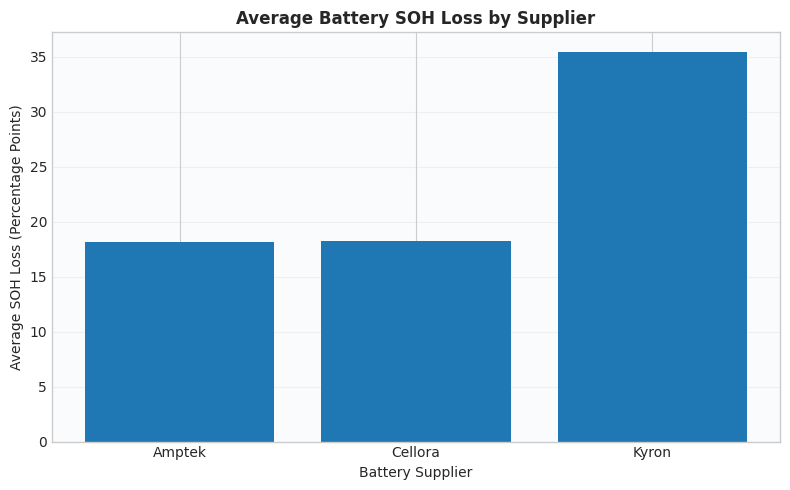


STEP 29 COMPLETE


In [82]:
print("=" * 70)
print("STEP 29 - BATTERY HEALTH VS RECORDED USAGE")
print("=" * 70)

# 1. Calculate SOH loss from initial to current/last recorded SOH
batteries["soh_loss_pp"] = (
    batteries["initial_soh_pct"] -
    batteries["current_soh_pct"]
)

# 2. Descriptive SOH loss per 100 recorded swaps
# This is NOT a causal degradation rate.
batteries["soh_loss_per_100_swaps"] = (
    batteries["soh_loss_pp"] /
    batteries["completed_swap_uses"].replace(0, np.nan)
    * 100
)

# 3. Supplier comparison
print("\n1. SOH LOSS BY SUPPLIER")

supplier_degradation = (
    batteries.groupby("supplier")
    .agg(
        battery_count=("battery_id", "count"),
        retired_batteries=("retired_date", "count"),
        avg_recorded_swaps=("completed_swap_uses", "mean"),
        avg_service_days=("service_days", "mean"),
        avg_soh_loss_pp=("soh_loss_pp", "mean"),
        median_soh_loss_pp=("soh_loss_pp", "median"),
        avg_loss_per_100_swaps=("soh_loss_per_100_swaps", "mean")
    )
    .reset_index()
)

display(supplier_degradation.round(2))

# 4. Compare by pack type to reduce mix differences
print("\n2. SOH LOSS BY SUPPLIER AND PACK TYPE")

pack_degradation = (
    batteries.groupby(["supplier", "pack_type"])
    .agg(
        battery_count=("battery_id", "count"),
        retired_batteries=("retired_date", "count"),
        avg_recorded_swaps=("completed_swap_uses", "mean"),
        avg_soh_loss_pp=("soh_loss_pp", "mean"),
        avg_loss_per_100_swaps=("soh_loss_per_100_swaps", "mean")
    )
    .reset_index()
)

display(pack_degradation.round(2))

# 5. Kyron lot comparison
print("\n3. KYRON MANUFACTURING LOT COMPARISON")

kyron_degradation = (
    batteries.loc[batteries["supplier"].eq("Kyron")]
    .groupby("manufacturing_lot")
    .agg(
        battery_count=("battery_id", "count"),
        retired_batteries=("retired_date", "count"),
        avg_recorded_swaps=("completed_swap_uses", "mean"),
        avg_service_days=("service_days", "mean"),
        avg_soh_loss_pp=("soh_loss_pp", "mean"),
        avg_loss_per_100_swaps=("soh_loss_per_100_swaps", "mean")
    )
    .reset_index()
)

display(
    kyron_degradation.sort_values(
        "avg_soh_loss_pp",
        ascending=False
    ).round(2)
)

# 6. Visual comparison
print("\n4. SUPPLIER SOH LOSS CHART")

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    supplier_degradation["supplier"],
    supplier_degradation["avg_soh_loss_pp"]
)

plt.title("Average Battery SOH Loss by Supplier")
plt.xlabel("Battery Supplier")
plt.ylabel("Average SOH Loss (Percentage Points)")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print("\nSTEP 29 COMPLETE")

STEP 30 - CUSTOMER SUPPORT AND SATISFACTION

1. SUPPORT TICKET CATEGORIES


,category,ticket_count,percentage
0,no_battery_available,11510,26.48
1,other,9385,21.59
2,low_range,6562,15.10
3,app_issue,5726,13.17
4,long_queue,5660,13.02
5,billing_dispute,4622,10.63



2. TICKET RESOLUTION STATUS


,resolution_status,ticket_count
0,resolved,37424
1,unresolved,5118
2,duplicate,923



3. RESOLUTION TIME BY CATEGORY


,category,total_tickets,tickets_with_resolution_time,avg_resolution_hours,median_resolution_hours,p90_resolution_hours
4,no_battery_available,11510,9878,15.96,13.4,29.30
5,other,9385,8056,16.04,13.1,29.80
3,low_range,6562,5652,15.99,13.1,29.79
0,app_issue,5726,4932,15.89,13.0,29.60
2,long_queue,5660,4902,15.82,13.1,28.70
1,billing_dispute,4622,4004,15.90,13.3,29.40



4. CUSTOMER SATISFACTION BY CATEGORY


,category,total_tickets,csat_responses,avg_csat,median_csat,csat_response_rate_pct
4,no_battery_available,11510,3957,3.60,4.0,34.38
5,other,9385,3212,3.57,4.0,34.22
3,low_range,6562,2304,3.53,4.0,35.11
0,app_issue,5726,1920,3.53,4.0,33.53
2,long_queue,5660,1969,3.50,4.0,34.79
1,billing_dispute,4622,1590,3.56,4.0,34.40



5. MONTHLY SUPPORT TICKET TREND


,month,ticket_count,csat_responses,avg_csat
0,2023-03,3,1,1.00
1,2023-04,1,1,1.00
2,2023-05,1,0,NaN
3,2023-07,1,0,NaN
4,2023-08,2,1,1.00
5,2023-09,1,0,NaN
6,2023-10,2,1,4.00
7,2023-11,1,0,NaN
8,2023-12,1,1,4.00
9,2024-01,654,231,3.63


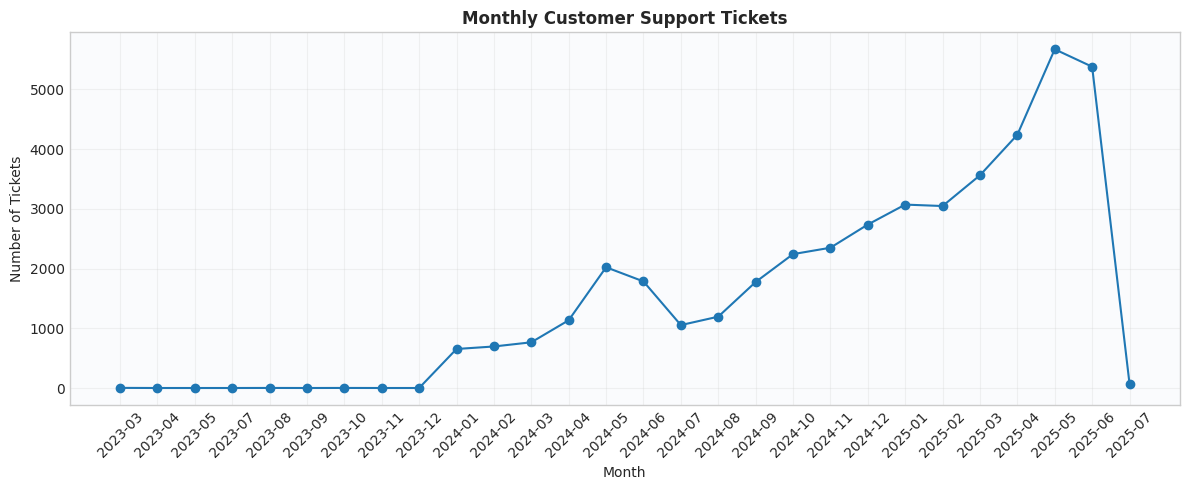


STEP 30 COMPLETE


In [83]:
print("=" * 70)
print("STEP 30 - CUSTOMER SUPPORT AND SATISFACTION")
print("=" * 70)

# Exclude test-station tickets from station-related analysis.
# Keep tickets with no station ID because they may be general complaints.
primary_tickets = tickets.loc[
    ~tickets["is_test_station"]
].copy()

# 1. Ticket category distribution
print("\n1. SUPPORT TICKET CATEGORIES")

category_summary = (
    primary_tickets["category"]
    .value_counts(dropna=False)
    .rename_axis("category")
    .reset_index(name="ticket_count")
)

category_summary["percentage"] = (
    category_summary["ticket_count"] /
    len(primary_tickets) * 100
).round(2)

display(category_summary)

# 2. Resolution status
print("\n2. TICKET RESOLUTION STATUS")

display(
    primary_tickets["resolution_status"]
    .value_counts(dropna=False)
    .rename_axis("resolution_status")
    .reset_index(name="ticket_count")
)

# 3. Resolution time by category
print("\n3. RESOLUTION TIME BY CATEGORY")

resolution_summary = (
    primary_tickets.groupby("category", dropna=False)
    .agg(
        total_tickets=("ticket_id", "count"),
        tickets_with_resolution_time=("resolution_hours", "count"),
        avg_resolution_hours=("resolution_hours", "mean"),
        median_resolution_hours=("resolution_hours", "median"),
        p90_resolution_hours=(
            "resolution_hours",
            lambda x: x.quantile(0.90)
        )
    )
    .reset_index()
)

display(
    resolution_summary.sort_values(
        "total_tickets", ascending=False
    ).round(2)
)

# 4. CSAT by category
print("\n4. CUSTOMER SATISFACTION BY CATEGORY")

csat_summary = (
    primary_tickets.groupby("category", dropna=False)
    .agg(
        total_tickets=("ticket_id", "count"),
        csat_responses=("csat_score", "count"),
        avg_csat=("csat_score", "mean"),
        median_csat=("csat_score", "median")
    )
    .reset_index()
)

csat_summary["csat_response_rate_pct"] = (
    csat_summary["csat_responses"] /
    csat_summary["total_tickets"] * 100
)

display(
    csat_summary.sort_values(
        "total_tickets", ascending=False
    ).round(2)
)

# 5. Monthly complaint trends
print("\n5. MONTHLY SUPPORT TICKET TREND")

primary_tickets["month"] = (
    primary_tickets["created_ts"]
    .dt.to_period("M")
    .astype(str)
)

monthly_tickets = (
    primary_tickets.groupby("month")
    .agg(
        ticket_count=("ticket_id", "count"),
        csat_responses=("csat_score", "count"),
        avg_csat=("csat_score", "mean")
    )
    .reset_index()
)

display(monthly_tickets.round(2))

# 6. Support ticket trend chart
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_tickets["month"],
    monthly_tickets["ticket_count"],
    marker="o"
)

plt.title("Monthly Customer Support Tickets")
plt.xlabel("Month")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=45)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("\nSTEP 30 COMPLETE")

STEP 31 - NORMALIZED CUSTOMER COMPLAINT TRENDS

1. TICKET DATE QUALITY CHECK
Tickets outside study period: 85
Tickets within study period: 43380

Out-of-period tickets by month:


,month,ticket_count
0,2023-03,3
1,2023-04,1
2,2023-05,1
3,2023-07,1
4,2023-08,2
5,2023-09,1
6,2023-10,2
7,2023-11,1
8,2023-12,1
9,2025-07,72



2. MONTHLY NORMALIZED COMPLAINT RATES


,month,swap_attempts,ticket_count,unique_complainants,tickets_per_1000_attempts,complainants_per_1000_attempts
0,2024-01,108278,654,602,6.04,5.56
1,2024-02,109271,696,624,6.37,5.71
2,2024-03,121487,766,704,6.31,5.79
3,2024-04,128991,1135,997,8.80,7.73
4,2024-05,143189,2022,1620,14.12,11.31
5,2024-06,145880,1785,1453,12.24,9.96
6,2024-07,155343,1054,962,6.78,6.19
7,2024-08,168900,1195,1060,7.08,6.28
8,2024-09,192479,1775,1542,9.22,8.01
9,2024-10,226458,2242,1900,9.90,8.39



3. COMPLAINT RATE VS SWAP FAILURE RATE


,month,tickets_per_1000_attempts,failure_rate_pct
0,2024-01,6.04,4.41
1,2024-02,6.37,4.42
2,2024-03,6.31,4.39
3,2024-04,8.80,6.88
4,2024-05,14.12,12.39
5,2024-06,12.24,10.28
6,2024-07,6.78,4.33
7,2024-08,7.08,4.27
8,2024-09,9.22,4.38
9,2024-10,9.90,4.37


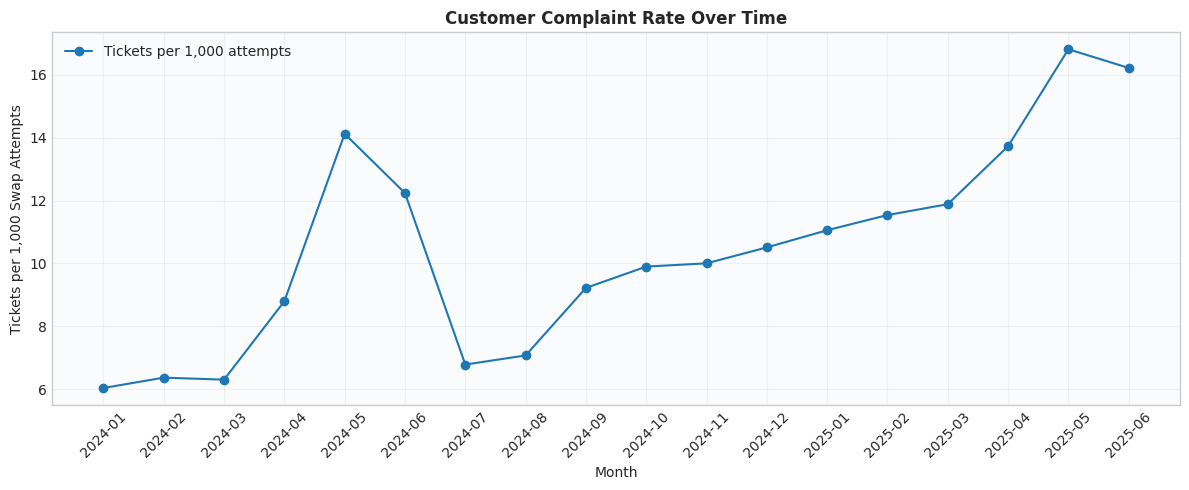


STEP 31 COMPLETE


In [84]:
print("=" * 70)
print("STEP 31 - NORMALIZED CUSTOMER COMPLAINT TRENDS")
print("=" * 70)

START_DATE = pd.Timestamp("2024-01-01")
END_DATE = pd.Timestamp("2025-07-01")

# 1. Investigate tickets outside the analysis period
print("\n1. TICKET DATE QUALITY CHECK")

outside_period = (
    primary_tickets["created_ts"].lt(START_DATE) |
    primary_tickets["created_ts"].ge(END_DATE)
)

print("Tickets outside study period:",
      outside_period.sum())

print("Tickets within study period:",
      (~outside_period).sum())

print("\nOut-of-period tickets by month:")
display(
    primary_tickets.loc[outside_period, "month"]
    .value_counts()
    .sort_index()
    .rename_axis("month")
    .reset_index(name="ticket_count")
)

# 2. Filter to the study period
valid_tickets = primary_tickets.loc[
    ~outside_period
].copy()

# 3. Monthly ticket counts
monthly_complaints = (
    valid_tickets.groupby("month")
    .agg(
        ticket_count=("ticket_id", "count"),
        unique_complainants=("rider_id", "nunique")
    )
    .reset_index()
)

# 4. Monthly swap attempts from primary network
monthly_attempts = (
    monthly_data.groupby("month")
    .size()
    .reset_index(name="swap_attempts")
)

# 5. Join monthly complaints with monthly attempts
complaint_rate = monthly_attempts.merge(
    monthly_complaints,
    on="month",
    how="left"
)

complaint_rate[
    ["ticket_count", "unique_complainants"]
] = complaint_rate[
    ["ticket_count", "unique_complainants"]
].fillna(0)

# 6. Calculate normalized rates
complaint_rate["tickets_per_1000_attempts"] = (
    complaint_rate["ticket_count"] /
    complaint_rate["swap_attempts"] * 1000
)

complaint_rate["complainants_per_1000_attempts"] = (
    complaint_rate["unique_complainants"] /
    complaint_rate["swap_attempts"] * 1000
)

print("\n2. MONTHLY NORMALIZED COMPLAINT RATES")
display(complaint_rate.round(2))

# 7. Compare with monthly swap failure rate
comparison = complaint_rate.merge(
    monthly_summary[["month", "failure_rate_pct"]],
    on="month",
    how="left"
)

print("\n3. COMPLAINT RATE VS SWAP FAILURE RATE")
display(
    comparison[
        ["month", "tickets_per_1000_attempts",
         "failure_rate_pct"]
    ].round(2)
)

# 8. Visualize the normalized trend
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    comparison["month"],
    comparison["tickets_per_1000_attempts"],
    marker="o",
    label="Tickets per 1,000 attempts"
)

plt.title("Customer Complaint Rate Over Time")
plt.xlabel("Month")
plt.ylabel("Tickets per 1,000 Swap Attempts")
plt.xticks(rotation=45)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

print("\nSTEP 31 COMPLETE")

In [85]:
print("=" * 70)
print("STEP 32 - RIDER RETENTION AND REPEAT USAGE")
print("=" * 70)

# 1. Keep only the columns needed for retention analysis
# Exclude test stations.
retention_events = swap_events.loc[
    ~swap_events["is_test_station"],
    ["rider_id", "event_ts_corrected", "event_type"]
].copy()

# Use calendar dates for repeat-usage analysis
retention_events["event_date"] = (
    retention_events["event_ts_corrected"].dt.normalize()
)

# 2. Find each rider's first observed event
first_event_index = (
    retention_events.groupby("rider_id")[
        "event_ts_corrected"
    ].idxmin()
)

first_events = (
    retention_events.loc[
        first_event_index,
        ["rider_id", "event_date", "event_type"]
    ]
    .copy()
)

first_events = first_events.rename(
    columns={
        "event_date": "first_event_date",
        "event_type": "first_event_type"
    }
)

# 3. Only include riders with a full 30-day observation window
# Last dataset day is 30 June 2025.
cutoff_date = pd.Timestamp("2025-05-31")

eligible_first_events = first_events.loc[
    first_events["first_event_date"].le(cutoff_date)
].copy()

# 4. Attach first-event dates to all events
retention_events = retention_events.merge(
    eligible_first_events[
        ["rider_id", "first_event_date"]
    ],
    on="rider_id",
    how="inner"
)

# 5. Calculate days after first observed event
retention_events["days_since_first"] = (
    retention_events["event_date"] -
    retention_events["first_event_date"]
).dt.days

# 6. A repeat means activity on another calendar day
# within 30 days of first observed activity.
repeat_riders = (
    retention_events.loc[
        retention_events["days_since_first"].between(1, 30),
        "rider_id"
    ]
    .unique()
)

eligible_first_events["returned_within_30d"] = (
    eligible_first_events["rider_id"].isin(repeat_riders)
)

# 7. Compare first-attempt outcomes
eligible_first_events["first_attempt_result"] = np.where(
    eligible_first_events["first_event_type"].eq("swap_completed"),
    "First attempt completed",
    "First attempt unsuccessful"
)

retention_summary = (
    eligible_first_events.groupby("first_attempt_result")
    .agg(
        riders=("rider_id", "count"),
        returned_30d=("returned_within_30d", "sum")
    )
    .reset_index()
)

retention_summary["repeat_usage_rate_pct"] = (
    retention_summary["returned_30d"] /
    retention_summary["riders"] * 100
).round(2)

retention_summary["no_repeat_rate_pct"] = (
    100 - retention_summary["repeat_usage_rate_pct"]
).round(2)

print("\n1. FIRST-ATTEMPT OUTCOME AND 30-DAY REPEAT USAGE")
display(retention_summary)

# 8. Detailed first-attempt outcome comparison
detailed_retention = (
    eligible_first_events.groupby("first_event_type")
    .agg(
        riders=("rider_id", "count"),
        returned_30d=("returned_within_30d", "sum")
    )
    .reset_index()
)

detailed_retention["repeat_usage_rate_pct"] = (
    detailed_retention["returned_30d"] /
    detailed_retention["riders"] * 100
).round(2)

print("\n2. REPEAT USAGE BY FIRST EVENT TYPE")
display(
    detailed_retention.sort_values(
        "riders", ascending=False
    )
)

# 9. Overall repeat usage
print("\n3. OVERALL 30-DAY REPEAT USAGE")

total_riders = len(eligible_first_events)
returning_riders = eligible_first_events[
    "returned_within_30d"
].sum()

print("Eligible riders:", total_riders)
print("Riders returning within 30 days:", returning_riders)
print("Riders with no repeat within 30 days:",
      total_riders - returning_riders)

print(
    "30-day repeat usage rate:",
    round(returning_riders / total_riders * 100, 2),
    "%"
)

print("\nSTEP 32 COMPLETE")

STEP 32 - RIDER RETENTION AND REPEAT USAGE

1. FIRST-ATTEMPT OUTCOME AND 30-DAY REPEAT USAGE


,first_attempt_result,riders,returned_30d,repeat_usage_rate_pct,no_repeat_rate_pct
0,First attempt completed,17669,17587,99.54,0.46
1,First attempt unsuccessful,1032,1028,99.61,0.39



2. REPEAT USAGE BY FIRST EVENT TYPE


,first_event_type,riders,returned_30d,repeat_usage_rate_pct
4,swap_completed,17669,17587,99.54
2,failed_no_charged_battery,582,580,99.66
0,abandoned_queue,306,305,99.67
1,cancelled_by_rider,102,102,100.00
3,failed_system_error,42,41,97.62



3. OVERALL 30-DAY REPEAT USAGE
Eligible riders: 18701
Riders returning within 30 days: 18615
Riders with no repeat within 30 days: 86
30-day repeat usage rate: 99.54 %

STEP 32 COMPLETE


In [86]:
print("=" * 70)
print("STEP 33 - LONGER-TERM RIDER RETENTION")
print("=" * 70)

# Use the first observed event date for each rider.
# Keep only riders with enough observation time.

DATA_END = pd.Timestamp("2025-06-30")

# Calculate whether each rider has activity in:
# Days 1-30, 31-60, and 61-90 after first observed event.

retention_events["days_since_first"] = (
    retention_events["event_date"] -
    retention_events["first_event_date"]
).dt.days

# Count distinct active days in each period
retention_events["active_1_30"] = (
    retention_events["days_since_first"].between(1, 30)
)

retention_events["active_31_60"] = (
    retention_events["days_since_first"].between(31, 60)
)

retention_events["active_61_90"] = (
    retention_events["days_since_first"].between(61, 90)
)

rider_activity = (
    retention_events.groupby("rider_id")
    .agg(
        active_days_1_30=("active_1_30", "sum"),
        active_days_31_60=("active_31_60", "sum"),
        active_days_61_90=("active_61_90", "sum")
    )
    .reset_index()
)

# Restrict to riders with a full 90-day observation window.
eligible_90d = first_events.loc[
    first_events["first_event_date"] <=
    DATA_END - pd.Timedelta(days=90)
].copy()

eligible_90d = eligible_90d.merge(
    rider_activity,
    on="rider_id",
    how="left"
)

for col in [
    "active_days_1_30",
    "active_days_31_60",
    "active_days_61_90"
]:
    eligible_90d[col] = eligible_90d[col].fillna(0)

# Create activity indicators
eligible_90d["returned_1_30"] = (
    eligible_90d["active_days_1_30"] > 0
)

eligible_90d["returned_31_60"] = (
    eligible_90d["active_days_31_60"] > 0
)

eligible_90d["returned_61_90"] = (
    eligible_90d["active_days_61_90"] > 0
)

eligible_90d["first_attempt_result"] = np.where(
    eligible_90d["first_event_type"].eq("swap_completed"),
    "First attempt completed",
    "First attempt unsuccessful"
)

# Summarize retention by first attempt outcome
long_term_summary = (
    eligible_90d.groupby("first_attempt_result")
    .agg(
        riders=("rider_id", "count"),
        returned_1_30=("returned_1_30", "sum"),
        returned_31_60=("returned_31_60", "sum"),
        returned_61_90=("returned_61_90", "sum")
    )
    .reset_index()
)

for period in ["1_30", "31_60", "61_90"]:
    long_term_summary[f"retention_{period}_pct"] = (
        long_term_summary[f"returned_{period}"] /
        long_term_summary["riders"] * 100
    ).round(2)

print("\n1. LONG-TERM RETENTION BY FIRST ATTEMPT")
display(long_term_summary)

# Overall retention
print("\n2. OVERALL LONG-TERM RETENTION")

total = len(eligible_90d)

print("Eligible riders:", total)

for period in ["1_30", "31_60", "61_90"]:
    count = eligible_90d[f"returned_{period}"].sum()
    rate = count / total * 100 if total else 0

    print(
        f"Days {period.replace('_', '-')}:",
        f"{count:,} riders ({rate:.2f}%)"
    )

print("\nSTEP 33 COMPLETE")

STEP 33 - LONGER-TERM RIDER RETENTION

1. LONG-TERM RETENTION BY FIRST ATTEMPT


,first_attempt_result,riders,returned_1_30,returned_31_60,returned_61_90,retention_1_30_pct,retention_31_60_pct,retention_61_90_pct
0,First attempt completed,15494,15424,13541,12708,99.55,87.40,82.02
1,First attempt unsuccessful,833,829,688,649,99.52,82.59,77.91



2. OVERALL LONG-TERM RETENTION
Eligible riders: 16327
Days 1-30: 16,253 riders (99.55%)
Days 31-60: 14,229 riders (87.15%)
Days 61-90: 13,357 riders (81.81%)

STEP 33 COMPLETE


In [87]:
print("=" * 70)
print("STEP 34 - RETENTION BY CUSTOMER SEGMENT")
print("=" * 70)

# 1. Attach rider information to the eligible 90-day cohort
rider_segments = riders[
    ["rider_id", "vehicle_class",
     "plan_type", "home_city_standard", "partner_id"]
].copy()

segment_retention = eligible_90d.merge(
    rider_segments,
    on="rider_id",
    how="left"
)

segment_retention["rider_type"] = np.where(
    segment_retention["partner_id"].notna(),
    "Fleet partner",
    "Independent"
)

# 2. Overall retention by city
print("\n1. RETENTION BY HOME CITY")

city_retention = (
    segment_retention.groupby("home_city_standard")
    .agg(
        riders=("rider_id", "count"),
        returned_61_90=("returned_61_90", "sum")
    )
    .reset_index()
)

city_retention["retention_pct"] = (
    city_retention["returned_61_90"] /
    city_retention["riders"] * 100
)

display(
    city_retention.sort_values(
        "retention_pct"
    ).round(2)
)

# 3. Retention by vehicle class and first attempt outcome
print("\n2. RETENTION BY VEHICLE CLASS AND FIRST ATTEMPT")

vehicle_retention = (
    segment_retention.groupby(
        ["vehicle_class", "first_attempt_result"]
    )
    .agg(
        riders=("rider_id", "count"),
        returned_61_90=("returned_61_90", "sum")
    )
    .reset_index()
)

vehicle_retention["retention_pct"] = (
    vehicle_retention["returned_61_90"] /
    vehicle_retention["riders"] * 100
)

display(vehicle_retention.round(2))

# 4. Retention by rider type
print("\n3. RETENTION BY RIDER TYPE")

rider_type_retention = (
    segment_retention.groupby(
        ["rider_type", "first_attempt_result"]
    )
    .agg(
        riders=("rider_id", "count"),
        returned_61_90=("returned_61_90", "sum")
    )
    .reset_index()
)

rider_type_retention["retention_pct"] = (
    rider_type_retention["returned_61_90"] /
    rider_type_retention["riders"] * 100
)

display(rider_type_retention.round(2))

# 5. Retention by city and first attempt
print("\n4. RETENTION GAP BY CITY")

city_first_attempt = (
    segment_retention.groupby(
        ["home_city_standard", "first_attempt_result"]
    )
    .agg(
        riders=("rider_id", "count"),
        returned_61_90=("returned_61_90", "sum")
    )
    .reset_index()
)

city_first_attempt["retention_pct"] = (
    city_first_attempt["returned_61_90"] /
    city_first_attempt["riders"] * 100
)

display(
    city_first_attempt.sort_values(
        ["home_city_standard", "first_attempt_result"]
    ).round(2)
)

print("\nSTEP 34 COMPLETE")

STEP 34 - RETENTION BY CUSTOMER SEGMENT

1. RETENTION BY HOME CITY


,home_city_standard,riders,returned_61_90,retention_pct
3,Jaipur,2035,1635,80.34
2,Hyderabad,2853,2325,81.49
1,Delhi NCR,3171,2586,81.55
5,Pune,2370,1934,81.60
0,Bengaluru,3544,2905,81.97
4,Mumbai,2354,1972,83.77



2. RETENTION BY VEHICLE CLASS AND FIRST ATTEMPT


,vehicle_class,first_attempt_result,riders,returned_61_90,retention_pct
0,2W,First attempt completed,13368,11016,82.41
1,2W,First attempt unsuccessful,598,472,78.93
2,3W,First attempt completed,2126,1692,79.59
3,3W,First attempt unsuccessful,235,177,75.32



3. RETENTION BY RIDER TYPE


,rider_type,first_attempt_result,riders,returned_61_90,retention_pct
0,Fleet partner,First attempt completed,9511,7739,81.37
1,Fleet partner,First attempt unsuccessful,540,411,76.11
2,Independent,First attempt completed,5983,4969,83.05
3,Independent,First attempt unsuccessful,293,238,81.23



4. RETENTION GAP BY CITY


,home_city_standard,first_attempt_result,riders,returned_61_90,retention_pct
0,Bengaluru,First attempt completed,3381,2775,82.08
1,Bengaluru,First attempt unsuccessful,163,130,79.75
2,Delhi NCR,First attempt completed,3007,2452,81.54
3,Delhi NCR,First attempt unsuccessful,164,134,81.71
4,Hyderabad,First attempt completed,2695,2210,82.00
5,Hyderabad,First attempt unsuccessful,158,115,72.78
6,Jaipur,First attempt completed,1905,1540,80.84
7,Jaipur,First attempt unsuccessful,130,95,73.08
8,Mumbai,First attempt completed,2253,1888,83.80
9,Mumbai,First attempt unsuccessful,101,84,83.17



STEP 34 COMPLETE


In [88]:
print("=" * 70)
print("STEP 35 - PRICING AND FLEET PARTNER ECONOMICS")
print("=" * 70)

# 1. Work with completed, non-test swaps only
completed_mask = (
    ~swap_events["is_test_station"] &
    swap_events["event_type"].eq("swap_completed")
)

# 2. Calculate revenue by tariff
print("\n1. REVENUE BY TARIFF")

tariff_summary = (
    swap_events.loc[completed_mask]
    .groupby("tariff_code")
    .agg(
        completed_swaps=("event_id", "count"),
        total_list_price=("list_price_inr", "sum"),
        total_discounts=("discount_inr", "sum"),
        total_revenue=("amount_charged_inr", "sum"),
        avg_revenue_per_swap=("amount_charged_inr", "mean")
    )
    .reset_index()
)

tariff_summary["discount_pct_of_list"] = (
    tariff_summary["total_discounts"] /
    tariff_summary["total_list_price"] * 100
)

display(
    tariff_summary.sort_values(
        "completed_swaps", ascending=False
    ).round(2)
)

# 3. Calculate revenue by rider plan
print("\n2. REVENUE BY RIDER PLAN")

rider_lookup = riders.set_index("rider_id")

plan_for_events = swap_events.loc[
    completed_mask, "rider_id"
].map(rider_lookup["plan_type"])

plan_summary = (
    swap_events.loc[
        completed_mask,
        ["amount_charged_inr", "discount_inr", "list_price_inr"]
    ]
    .groupby(plan_for_events)
    .agg(
        completed_swaps=("amount_charged_inr", "count"),
        revenue=("amount_charged_inr", "sum"),
        discounts=("discount_inr", "sum"),
        list_price=("list_price_inr", "sum"),
        avg_revenue_per_swap=("amount_charged_inr", "mean")
    )
    .reset_index()
    .rename(columns={"rider_id": "plan_type"})
)

display(plan_summary.round(2))

# 4. Revenue by fleet partner
print("\n3. FLEET PARTNER REVENUE")

partner_for_events = swap_events.loc[
    completed_mask, "rider_id"
].map(rider_lookup["partner_id"])

partner_revenue = (
    swap_events.loc[
        completed_mask,
        ["amount_charged_inr", "discount_inr", "list_price_inr"]
    ]
    .groupby(partner_for_events, dropna=False)
    .agg(
        completed_swaps=("amount_charged_inr", "count"),
        total_revenue=("amount_charged_inr", "sum"),
        total_discounts=("discount_inr", "sum"),
        total_list_price=("list_price_inr", "sum"),
        avg_revenue_per_swap=("amount_charged_inr", "mean")
    )
    .reset_index()
    .rename(columns={"rider_id": "partner_id"})
)

partner_revenue = partner_revenue.merge(
    fleet_partners[
        ["partner_id", "partner_name",
         "partner_segment", "contract_type"]
    ],
    on="partner_id",
    how="left"
)

partner_revenue["partner_name"] = (
    partner_revenue["partner_name"]
    .fillna("Independent riders")
)

partner_revenue["discount_pct_of_list"] = (
    partner_revenue["total_discounts"] /
    partner_revenue["total_list_price"] * 100
)

display(
    partner_revenue.sort_values(
        "total_revenue", ascending=False
    ).round(2)
)

# 5. Compare fleet versus independent economics
print("\n4. FLEET VS INDEPENDENT REVENUE")

partner_revenue["rider_group"] = np.where(
    partner_revenue["partner_id"].isna(),
    "Independent",
    "Fleet partner"
)

fleet_vs_independent = (
    partner_revenue.groupby("rider_group")
    .agg(
        completed_swaps=("completed_swaps", "sum"),
        revenue=("total_revenue", "sum"),
        discounts=("total_discounts", "sum"),
        list_price=("total_list_price", "sum")
    )
    .reset_index()
)

fleet_vs_independent["avg_revenue_per_swap"] = (
    fleet_vs_independent["revenue"] /
    fleet_vs_independent["completed_swaps"]
)

fleet_vs_independent["discount_pct_of_list"] = (
    fleet_vs_independent["discounts"] /
    fleet_vs_independent["list_price"] * 100
)

display(fleet_vs_independent.round(2))

print("\nSTEP 35 COMPLETE")

STEP 35 - PRICING AND FLEET PARTNER ECONOMICS

1. REVENUE BY TARIFF


,tariff_code,completed_swaps,total_list_price,total_discounts,total_revenue,avg_revenue_per_swap,discount_pct_of_list
1,PARTNER,2368154,165061080.0,20875332.5,146079774.5,61.69,12.65
3,STD,1019766,67519880.0,0.0,67519860.0,66.21,0.00
2,PEAK,163922,11064880.0,0.0,13523775.0,82.50,0.00
0,OFFPEAK,34833,2350455.0,0.0,2071886.0,59.48,0.00



2. REVENUE BY RIDER PLAN


,plan_type,completed_swaps,revenue,discounts,list_price,avg_revenue_per_swap
0,partner_billed,2368154,146079774.5,20875332.5,165061080.0,61.69
1,pay_as_you_go,846438,57756019.0,0.0,56265535.0,68.23
2,prepaid_pack,372083,25359502.0,0.0,24669680.0,68.16



3. FLEET PARTNER REVENUE


,partner_id,completed_swaps,total_revenue,total_discounts,total_list_price,avg_revenue_per_swap,partner_name,partner_segment,contract_type,discount_pct_of_list
12,NaN,1218521,83115521.00,0.00,80935215.0,68.21,Independent riders,NaN,NaN,0.00
0,FP-01,516367,32027884.50,3429955.50,34299555.0,62.03,FeastFly,food_delivery,volume_tiered,10.00
2,FP-03,549390,28606514.80,8033300.20,36639675.0,52.07,ZipDrop,quick_commerce,volume_tiered,21.93
1,FP-02,296209,16740212.75,2945483.25,19636555.0,56.51,ParcelNest,ecom_logistics,pay_per_swap,15.00
4,FP-05,237632,14092428.90,1741741.10,15834010.0,59.30,Swiggle Go,food_delivery,volume_tiered,11.00
3,FP-04,131334,13062630.80,1134503.20,14181290.0,99.46,CargoTuk,cargo_3w,pay_per_swap,8.00
6,FP-07,127961,7934508.55,757764.45,8419605.0,62.01,QuickCart,quick_commerce,pay_per_swap,9.00
5,FP-06,119503,7494595.50,473170.50,7886175.0,62.71,RideMitra,bike_taxi,pay_per_swap,6.00
7,FP-08,92027,5853723.60,489558.40,6119480.0,63.61,DabbaXpress,food_delivery,pay_per_swap,8.00
8,FP-09,53120,5331093.20,400955.80,5727940.0,100.36,HaulKing,cargo_3w,pay_per_swap,7.00



4. FLEET VS INDEPENDENT REVENUE


,rider_group,completed_swaps,revenue,discounts,list_price,avg_revenue_per_swap,discount_pct_of_list
0,Fleet partner,2368154,146079774.5,20875332.5,165061080.0,61.69,12.65
1,Independent,1218521,83115521.0,0.0,80935215.0,68.21,0.00



STEP 35 COMPLETE


In [89]:
print("=" * 70)
print("STEP 36 - PRICING RECONCILIATION")
print("=" * 70)

# Only completed, non-test swaps
pricing_cols = [
    "tariff_code",
    "list_price_inr",
    "discount_inr",
    "amount_charged_inr"
]

pricing = swap_events.loc[
    completed_mask, pricing_cols
].copy()

# Expected charge if discounts were the only adjustment
pricing["expected_charge"] = (
    pricing["list_price_inr"] -
    pricing["discount_inr"]
)

# Positive = charged more than expected
# Negative = charged less than expected
pricing["other_adjustment"] = (
    pricing["amount_charged_inr"] -
    pricing["expected_charge"]
)

pricing["has_adjustment"] = (
    pricing["other_adjustment"].abs() > 0.01
)

print("\n1. PRICING RECONCILIATION BY TARIFF")

reconciliation = (
    pricing.groupby("tariff_code")
    .agg(
        swaps=("amount_charged_inr", "count"),
        list_price=("list_price_inr", "sum"),
        recorded_discounts=("discount_inr", "sum"),
        actual_revenue=("amount_charged_inr", "sum"),
        total_other_adjustment=("other_adjustment", "sum"),
        avg_other_adjustment=("other_adjustment", "mean"),
        adjusted_swaps=("has_adjustment", "sum")
    )
    .reset_index()
)

reconciliation["adjusted_swaps_pct"] = (
    reconciliation["adjusted_swaps"] /
    reconciliation["swaps"] * 100
)

display(reconciliation.round(2))

print("\n2. OVERALL RECONCILIATION")

print(
    "Total actual revenue: ₹",
    round(pricing["amount_charged_inr"].sum(), 2)
)

print(
    "Total expected revenue: ₹",
    round(pricing["expected_charge"].sum(), 2)
)

print(
    "Net other pricing adjustments: ₹",
    round(pricing["other_adjustment"].sum(), 2)
)

print(
    "Swaps with nonzero adjustments:",
    int(pricing["has_adjustment"].sum())
)

print("\n3. ADJUSTMENT DISTRIBUTION")

display(
    pricing.groupby("tariff_code")["other_adjustment"]
    .describe(percentiles=[0.1, 0.5, 0.9])
    .round(2)
)

del pricing

print("\nSTEP 36 COMPLETE")

STEP 36 - PRICING RECONCILIATION

1. PRICING RECONCILIATION BY TARIFF


,tariff_code,swaps,list_price,recorded_discounts,actual_revenue,total_other_adjustment,avg_other_adjustment,adjusted_swaps,adjusted_swaps_pct
0,OFFPEAK,34833,2350455.0,0.0,2071886.0,-278569.0,-8.0,34833,100.00
1,PARTNER,2368154,165061080.0,20875332.5,146079774.5,1894027.0,0.8,237967,10.05
2,PEAK,163922,11064880.0,0.0,13523775.0,2458895.0,15.0,163922,100.00
3,STD,1019766,67519880.0,0.0,67519860.0,-20.0,-0.0,2082,0.20



2. OVERALL RECONCILIATION
Total actual revenue: ₹ 229195295.5
Total expected revenue: ₹ 225120962.5
Net other pricing adjustments: ₹ 4074333.0
Swaps with nonzero adjustments: 438804

3. ADJUSTMENT DISTRIBUTION


,count,mean,std,min,10%,50%,90%,max
tariff_code,,,,,,,,
OFFPEAK,34833.0,-8.0,0.41,-18.0,-8.0,-8.0,-8.0,2.0
PARTNER,2368154.0,0.8,4.11,-18.0,0.0,0.0,0.0,25.0
PEAK,163922.0,15.0,0.34,5.0,15.0,15.0,15.0,25.0
STD,1019766.0,-0.0,0.36,-10.0,0.0,0.0,0.0,10.0



STEP 36 COMPLETE


STEP 37 - FINAL COLORFUL EXECUTIVE DASHBOARD

FINAL EXECUTIVE DASHBOARD



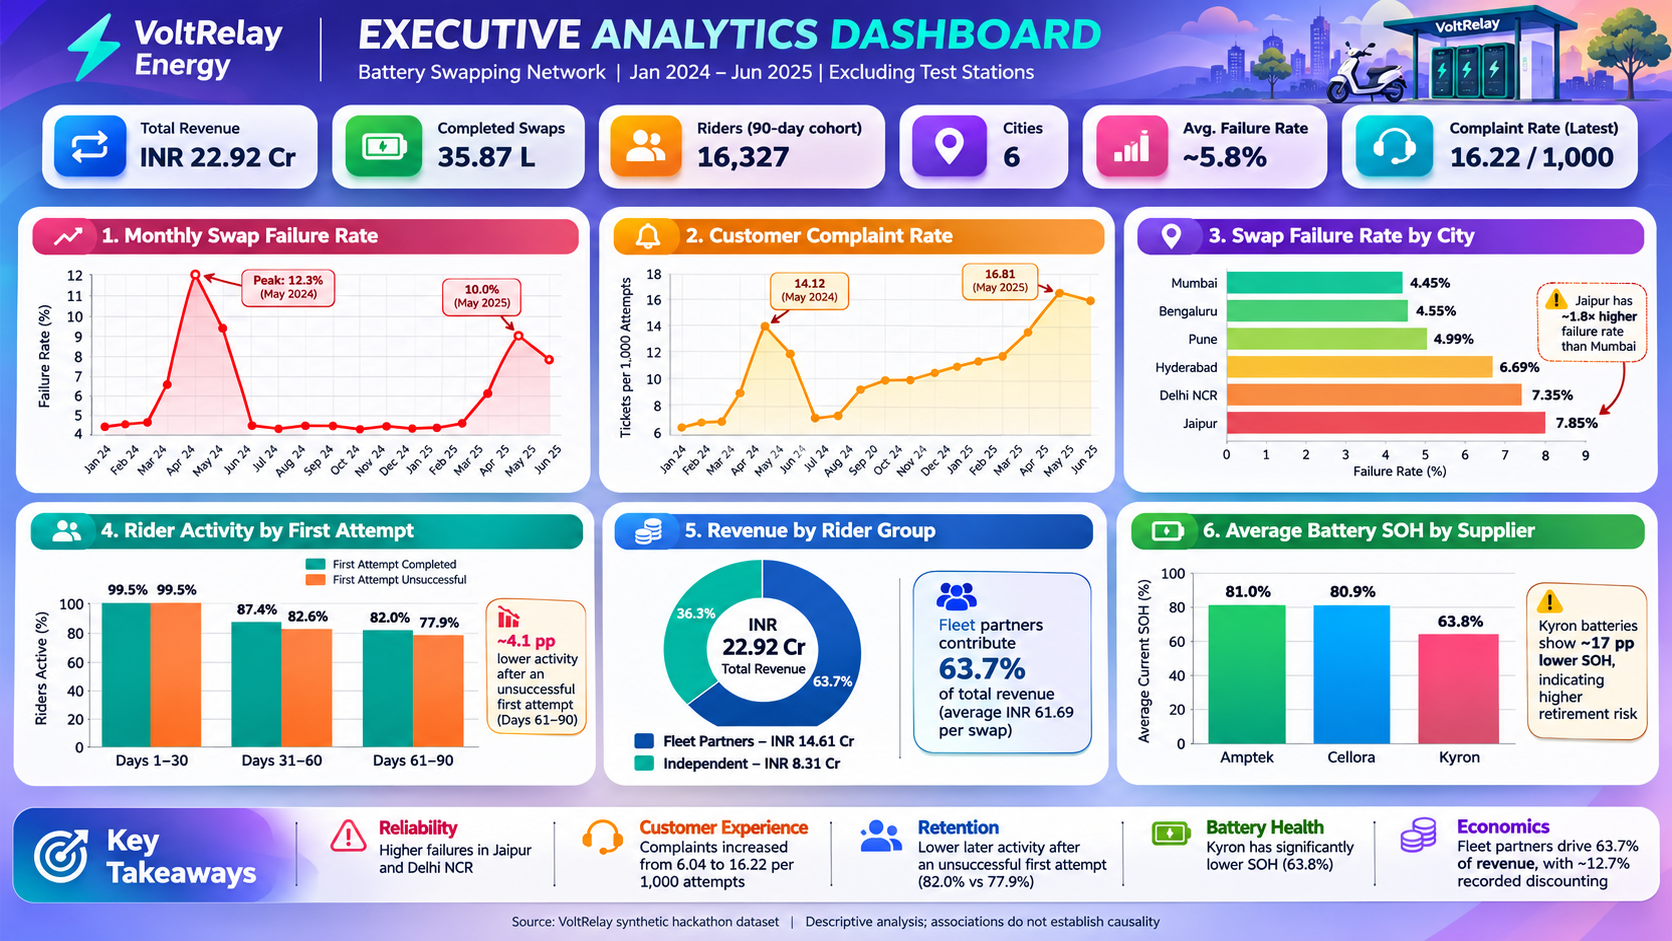


FINAL DASHBOARD LOADED SUCCESSFULLY!
Dashboard: VoltRelay_Executive_Dashboard.png
Location: /content/drive/MyDrive/VoltRelay_Hackathon_Results/VoltRelay_Executive_Dashboard.png
File exists: True
File size: 1.76 MB

STEP 37 COMPLETE
Dashboard is ready for final submission!


In [91]:

# ============================================================
# STEP 37 - FINAL COLORFUL EXECUTIVE DASHBOARD
# ============================================================

import os
from google.colab import drive
from IPython.display import display, Image

print("=" * 70)
print("STEP 37 - FINAL COLORFUL EXECUTIVE DASHBOARD")
print("=" * 70)

# STEP 1: Connect Google Drive if needed
if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")

# STEP 2: Set dashboard location
output_dir = "/content/drive/MyDrive/VoltRelay_Hackathon_Results"

dashboard_path = os.path.join(
    output_dir,
    "VoltRelay_Executive_Dashboard.png"
)

# STEP 3: Verify dashboard
if not os.path.isfile(dashboard_path):
    raise FileNotFoundError(
        "Dashboard not found in Google Drive!\n"
        f"Expected location: {dashboard_path}\n"
        "Please check that Step 37's dashboard was saved."
    )

# STEP 4: Display final colorful dashboard
print("\nFINAL EXECUTIVE DASHBOARD\n")

display(
    Image(
        filename=dashboard_path,
        width=1200
    )
)

# STEP 5: Verify final output
file_size = os.path.getsize(dashboard_path) / (1024 * 1024)

print("\n" + "=" * 70)
print("FINAL DASHBOARD LOADED SUCCESSFULLY!")
print("=" * 70)

print("Dashboard:", os.path.basename(dashboard_path))
print("Location:", dashboard_path)
print("File exists:", os.path.exists(dashboard_path))
print("File size:", round(file_size, 2), "MB")

print("\nSTEP 37 COMPLETE")
print("Dashboard is ready for final submission!")


In [92]:

# ==============================================================
# STEP 38 - FINAL PROFESSIONAL PDF ANALYTICS REPORT
# VOLTRELAY ENERGY | DATA ANALYTICS HACKATHON 2026
# ==============================================================

import os
import sys
import subprocess
from datetime import datetime

# Install PDF library if needed
try:
    import reportlab
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "reportlab"
    ])

from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle,
    Image, PageBreak, KeepTogether, HRFlowable
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER, TA_LEFT
from reportlab.lib.pagesizes import A4, landscape
from reportlab.lib.units import inch
from reportlab.lib.utils import ImageReader

print("=" * 70)
print("STEP 38 - FINAL PROFESSIONAL PDF ANALYTICS REPORT")
print("=" * 70)

# --------------------------------------------------------------
# 1. OUTPUT SETTINGS
# --------------------------------------------------------------

OUTPUT_DIR = "/content/drive/MyDrive/VoltRelay_Hackathon_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

PDF_PATH = os.path.join(
    OUTPUT_DIR,
    "VoltRelay_Final_Analytics_Report.pdf"
)

DASHBOARD_PATH = os.path.join(
    OUTPUT_DIR,
    "VoltRelay_Executive_Dashboard.png"
)

# Use a wide A4 page for charts and tables
PAGE_SIZE = landscape(A4)
PAGE_WIDTH, PAGE_HEIGHT = PAGE_SIZE

MARGIN = 38
CONTENT_WIDTH = PAGE_WIDTH - 2 * MARGIN

# --------------------------------------------------------------
# 2. COLOR PALETTE
# --------------------------------------------------------------

NAVY = colors.HexColor("#142D4E")
BLUE = colors.HexColor("#2463EB")
CYAN = colors.HexColor("#06B6D4")
TEAL = colors.HexColor("#0F9F90")
PURPLE = colors.HexColor("#7451DA")
ORANGE = colors.HexColor("#F59E0B")
RED = colors.HexColor("#DC4B4B")
WHITE = colors.white
LIGHT = colors.HexColor("#F2F6FC")
PALE = colors.HexColor("#E9F0FA")
GRAY = colors.HexColor("#53657A")
DARK = colors.HexColor("#1C2A3A")

# --------------------------------------------------------------
# 3. DOCUMENT STYLES
# --------------------------------------------------------------

styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="ReportTitleCustom",
    fontName="Helvetica-Bold",
    fontSize=27,
    leading=34,
    textColor=NAVY,
    alignment=TA_CENTER,
    spaceAfter=16
))

styles.add(ParagraphStyle(
    name="ReportSubtitleCustom",
    fontName="Helvetica",
    fontSize=13,
    leading=19,
    textColor=GRAY,
    alignment=TA_CENTER,
    spaceAfter=14
))

styles.add(ParagraphStyle(
    name="SectionCustom",
    fontName="Helvetica-Bold",
    fontSize=17,
    leading=22,
    textColor=NAVY,
    spaceBefore=16,
    spaceAfter=11
))

styles.add(ParagraphStyle(
    name="SubsectionCustom",
    fontName="Helvetica-Bold",
    fontSize=11.5,
    leading=16,
    textColor=BLUE,
    spaceBefore=10,
    spaceAfter=7
))

styles.add(ParagraphStyle(
    name="BodyCustom",
    fontName="Helvetica",
    fontSize=9.6,
    leading=15,
    textColor=DARK,
    spaceAfter=9
))

styles.add(ParagraphStyle(
    name="SmallCustom",
    fontName="Helvetica",
    fontSize=8,
    leading=12,
    textColor=GRAY,
    spaceAfter=6
))

styles.add(ParagraphStyle(
    name="BulletCustom",
    fontName="Helvetica",
    fontSize=9.3,
    leading=14,
    leftIndent=15,
    firstLineIndent=-10,
    textColor=DARK,
    spaceAfter=6
))

styles.add(ParagraphStyle(
    name="TableHeadCustom",
    fontName="Helvetica-Bold",
    fontSize=8.4,
    leading=11,
    textColor=WHITE
))

styles.add(ParagraphStyle(
    name="TableBodyCustom",
    fontName="Helvetica",
    fontSize=8.1,
    leading=11,
    textColor=DARK
))

story = []

def add_title(text):
    story.append(Paragraph(text, styles["SectionCustom"]))

def add_subtitle(text):
    story.append(Paragraph(text, styles["SubsectionCustom"]))

def add_body(text):
    story.append(Paragraph(text, styles["BodyCustom"]))

def add_bullet(text):
    story.append(Paragraph(
        "&#8226; " + text,
        styles["BulletCustom"]
    ))

def add_gap(height=10):
    story.append(Spacer(1, height))

def add_table(headers, rows, widths=None):
    data = [
        [Paragraph(str(x), styles["TableHeadCustom"]) for x in headers]
    ]
    for row in rows:
        data.append([
            Paragraph(str(x), styles["TableBodyCustom"])
            for x in row
        ])

    if widths is None:
        widths = [CONTENT_WIDTH / len(headers)] * len(headers)

    t = Table(data, colWidths=widths, repeatRows=1, hAlign="LEFT")
    t.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), NAVY),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1), [WHITE, LIGHT]),
        ("GRID", (0, 0), (-1, -1), 0.35, PALE),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("LEFTPADDING", (0, 0), (-1, -1), 9),
        ("RIGHTPADDING", (0, 0), (-1, -1), 9),
        ("TOPPADDING", (0, 0), (-1, -1), 7),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 7),
    ]))
    story.append(t)
    add_gap(12)

# --------------------------------------------------------------
# 4. PAGE HEADER AND FOOTER
# --------------------------------------------------------------

def draw_page(canvas, doc):
    canvas.saveState()

    w, h = PAGE_SIZE

    canvas.setFillColor(NAVY)
    canvas.rect(0, h - 14, w, 14, stroke=0, fill=1)

    canvas.setStrokeColor(PALE)
    canvas.line(MARGIN, 31, w - MARGIN, 31)

    canvas.setFont("Helvetica", 7.5)
    canvas.setFillColor(GRAY)

    canvas.drawString(
        MARGIN, 19,
        "VOLTRELAY ENERGY | DATA ANALYTICS HACKATHON 2026"
    )

    canvas.drawRightString(
        w - MARGIN, 19,
        f"Page {doc.page}"
    )

    canvas.restoreState()

# --------------------------------------------------------------
# 5. COVER PAGE
# --------------------------------------------------------------

add_gap(65)

story.append(Paragraph(
    "VOLTRELAY ENERGY",
    styles["ReportTitleCustom"]
))

story.append(Paragraph(
    "Scaling Battery Swapping Through Data-Driven Decisions",
    styles["ReportSubtitleCustom"]
))

story.append(HRFlowable(
    width="65%",
    thickness=3,
    color=CYAN,
    hAlign="CENTER"
))

add_gap(25)

story.append(Paragraph(
    "FINAL BUSINESS ANALYTICS REPORT",
    styles["ReportTitleCustom"]
))

story.append(Paragraph(
    "Network Performance | Operational Reliability | Battery Health | "
    "Rider Retention | Revenue Economics",
    styles["ReportSubtitleCustom"]
))

add_gap(18)

story.append(Paragraph(
    "Analysis period: January 2024 - June 2025",
    styles["ReportSubtitleCustom"]
))

story.append(Paragraph(
    "Prepared for: Gradient Learnings Data Analytics Hackathon",
    styles["ReportSubtitleCustom"]
))

story.append(Paragraph(
    "Submission date: 15 November 2026",
    styles["ReportSubtitleCustom"]
))

add_gap(30)

add_body(
    "<b>Dataset note:</b> This analysis uses a synthetic battery-swapping "
    "business dataset. Results describe patterns within the supplied "
    "dataset and should not be interpreted as verified real-world "
    "performance of an operating company."
)

story.append(PageBreak())

# --------------------------------------------------------------
# 6. EXECUTIVE SUMMARY
# --------------------------------------------------------------

add_title("1. Executive Summary")

add_body(
    "VoltRelay Energy operates a battery-swapping network serving electric "
    "two-wheelers and three-wheelers across six Indian urban markets. "
    "The analysis covers 18 months of swap transactions, station "
    "telemetry, battery records, rider profiles, customer support "
    "tickets and fleet-partner information."
)

add_body(
    "The network demonstrates strong transaction growth and substantial "
    "revenue generation. However, service reliability, charged-battery "
    "availability, customer complaints and battery-health differences "
    "create opportunities for targeted operational improvement."
)

add_subtitle("Executive KPI Scorecard")

add_table(
    ["Metric", "Result", "Business interpretation"],
    [
        ["Swap attempts", "3,814,982", "Non-test network activity"],
        ["Completed swaps", "3,586,675", "94.02% completion rate"],
        ["Unsuccessful attempts", "228,307", "5.98% of attempts"],
        ["Total revenue", "INR 22.92 crore", "Completed-swap charges"],
        ["Operating cities", "6", "Multi-city network"],
        ["Network stations", "150", "Excluding 2 test stations"],
        ["Eligible 90-day rider cohort", "16,327", "First observed by 1 April 2025"],
    ],
    [185, 135, CONTENT_WIDTH - 320]
)

add_subtitle("Most Important Findings")

add_bullet(
    "<b>Reliability:</b> Jaipur (7.85%) and Delhi NCR (7.35%) "
    "record the highest city-level unsuccessful-swap rates."
)

add_bullet(
    "<b>Inventory:</b> Attempts associated with zero charged-battery "
    "stock have higher failure rates than attempts with available stock."
)

add_bullet(
    "<b>Customer experience:</b> Monthly ticket rates rise from "
    "6.04 to 16.22 per 1,000 swap attempts between January 2024 "
    "and June 2025."
)

add_bullet(
    "<b>Retention:</b> Days 61-90 activity is 82.02% for riders whose "
    "first observed attempt succeeded, versus 77.91% for those "
    "whose first attempt was unsuccessful."
)

add_bullet(
    "<b>Battery health:</b> Retirements are concentrated in three "
    "older Kyron manufacturing lots."
)

add_bullet(
    "<b>Economics:</b> Fleet partners account for approximately "
    "63.7% of completed-swap revenue."
)

story.append(PageBreak())

# --------------------------------------------------------------
# 7. BUSINESS PROBLEM AND METHODOLOGY
# --------------------------------------------------------------

add_title("2. Business Problem and Analytical Approach")

add_body(
    "The core business challenge is to support network growth while "
    "maintaining reliable battery availability, acceptable queue times, "
    "healthy battery inventory, customer retention and sustainable "
    "commercial relationships."
)

add_subtitle("Data Sources")

add_table(
    ["Dataset", "Approximate records", "Purpose"],
    [
        ["Swap events", "3,877,013", "Transactions and outcomes"],
        ["Station status", "1,487,712", "Inventory and operations"],
        ["Riders", "20,000", "Plans and rider segments"],
        ["Batteries", "6,500", "Health, supplier and retirement"],
        ["Support tickets", "44,000", "Customer experience"],
        ["Stations", "152", "Station attributes and geography"],
        ["City context", "3,282", "City-level contextual information"],
        ["Fleet partners", "12", "Partner and contract attributes"],
    ],
    [170, 135, CONTENT_WIDTH - 305]
)

add_subtitle("Data Cleaning and Quality Controls")

add_bullet(
    "Excluded two test stations and their associated swap activity "
    "from primary network metrics."
)

add_bullet(
    "Corrected a documented timestamp offset affecting 139,490 "
    "firmware v3.2.0 swap records."
)

add_bullet(
    "Standardized city names and checked event outcomes, distances, "
    "battery state-of-charge values and missing data."
)

add_bullet(
    "Separated completed and unsuccessful attempts to avoid "
    "inflating success and revenue metrics."
)

add_bullet(
    "Restricted retention cohorts to riders with enough observation "
    "time for the relevant follow-up window."
)

add_bullet(
    "Excluded out-of-window support tickets from monthly complaint "
    "rates and normalized tickets per 1,000 swap attempts."
)

add_subtitle("Interpretation Rules")

add_body(
    "Findings are descriptive and observational. A statistical "
    "association between inventory, failed swaps and rider activity "
    "does not establish that one factor directly caused another. "
    "Supplier comparisons are also influenced by manufacturing cohort, "
    "battery age, vehicle type and usage exposure."
)

story.append(PageBreak())

# --------------------------------------------------------------
# 8. DASHBOARD
# --------------------------------------------------------------

add_title("3. Executive Analytics Dashboard")

add_body(
    "The dashboard summarizes the six principal analytical views: "
    "monthly reliability, customer complaints, city performance, "
    "rider activity, revenue mix and battery health."
)

if os.path.exists(DASHBOARD_PATH):
    reader = ImageReader(DASHBOARD_PATH)
    image_width, image_height = reader.getSize()

    max_width = CONTENT_WIDTH
    max_height = PAGE_HEIGHT - 165

    scale = min(
        max_width / image_width,
        max_height / image_height
    )

    story.append(Image(
        DASHBOARD_PATH,
        width=image_width * scale,
        height=image_height * scale
    ))

    add_gap(8)
    story.append(Paragraph(
        "Visual summary based on the VoltRelay synthetic dataset. "
        "Use the verified numerical tables in this report as the "
        "authoritative source for exact values.",
        styles["SmallCustom"]
    ))
else:
    add_body(
        "Dashboard image not found. Check the Step 37 output folder."
    )

story.append(PageBreak())

# --------------------------------------------------------------
# 9. NETWORK PERFORMANCE
# --------------------------------------------------------------

add_title("4. Network Performance and Reliability")

add_body(
    "Across 3.81 million non-test swap attempts, the network "
    "completed 3.59 million swaps. The overall unsuccessful-attempt "
    "rate was approximately 5.98%."
)

add_subtitle("City-Level Failure Rates")

add_table(
    ["City", "Attempts", "Failure rate", "Priority"],
    [
        ["Jaipur", "487,634", "7.85%", "High"],
        ["Delhi NCR", "768,913", "7.35%", "High"],
        ["Hyderabad", "711,930", "6.69%", "Elevated"],
        ["Pune", "552,910", "4.99%", "Monitor"],
        ["Bengaluru", "763,296", "4.55%", "Monitor"],
        ["Mumbai", "530,299", "4.45%", "Monitor"],
    ],
    [170, 160, 150, CONTENT_WIDTH - 480]
)

add_subtitle("Failure Categories")

add_table(
    ["Outcome", "Attempts", "Share of all attempts"],
    [
        ["No charged battery", "132,786", "3.48%"],
        ["Queue abandonment", "67,663", "1.77%"],
        ["Cancelled", "16,458", "0.43%"],
        ["System error", "11,400", "0.30%"],
    ]
)

add_body(
    "The largest unsuccessful outcome category is the absence "
    "of a charged battery. Queue abandonment is the second-largest "
    "category. These results support prioritizing inventory "
    "availability and waiting-time management."
)

add_subtitle("Demand and Operational Stress")

add_bullet(
    "Swap demand is concentrated in evening hours, particularly "
    "between 19:00 and 22:00."
)

add_bullet(
    "Charged-battery stockouts also exhibit an afternoon pattern, "
    "with elevated zero-stock observations around 14:00-16:00."
)

add_bullet(
    "The median recorded queue time for completed swaps is "
    "209 seconds, versus 648 seconds for abandoned attempts."
)

story.append(PageBreak())

# --------------------------------------------------------------
# 10. INVENTORY AND BATTERY HEALTH
# --------------------------------------------------------------

add_title("5. Inventory Availability and Battery Health")

add_subtitle("Inventory-Linked Failure Rates")

add_table(
    ["Vehicle", "Stock status", "Attempts", "Failure rate"],
    [
        ["2W", "Charged stock available", "3,326,342", "5.36%"],
        ["2W", "Zero charged stock", "50,382", "10.98%"],
        ["3W", "Charged stock available", "172,847", "10.15%"],
        ["3W", "Zero charged stock", "4,283", "19.15%"],
    ]
)

add_body(
    "Failure rates are substantially higher when vehicle-matched "
    "charged-battery inventory is zero. This comparison excludes "
    "attempts where the relevant inventory status is unavailable. "
    "It is evidence of an operational association, not a controlled "
    "causal estimate."
)

add_subtitle("Battery Supplier Comparison")

add_table(
    ["Supplier", "Battery count", "Mean current SOH", "Retired"],
    [
        ["Amptek", "1,307", "81.01%", "0"],
        ["Cellora", "3,555", "80.93%", "0"],
        ["Kyron", "1,638", "63.75%", "1,438"],
    ]
)

add_body(
    "All 1,438 observed retired batteries belong to the Kyron "
    "supplier group, with retirements concentrated in the older "
    "KY-2407, KY-2408 and KY-2409 manufacturing lots. These lots "
    "contain 1,461 batteries in total."
)

add_body(
    "This concentration merits a targeted technical investigation. "
    "It does not, on its own, prove supplier defects because older "
    "batteries may have longer service exposure and different "
    "usage histories."
)

add_subtitle("Recommended Battery Actions")

add_bullet(
    "Audit the three older Kyron manufacturing lots and compare "
    "battery age, vehicle type, cycle exposure and health decline."
)

add_bullet(
    "Introduce a battery-health risk dashboard with SOH bands, "
    "retirement alerts and cohort-specific degradation tracking."
)

add_bullet(
    "Review spare-battery and charging allocation policies at "
    "high-failure stations."
)

story.append(PageBreak())

# --------------------------------------------------------------
# 11. CUSTOMER EXPERIENCE AND RETENTION
# --------------------------------------------------------------

add_title("6. Customer Experience and Rider Retention")

add_subtitle("Support Ticket Trends")

add_body(
    "The network recorded 43,380 non-test support tickets within "
    "the January 2024 to June 2025 analysis period. The monthly "
    "complaint rate increased from 6.04 to 16.22 tickets per "
    "1,000 swap attempts."
)

add_table(
    ["Support category", "Primary tickets", "Share of primary tickets"],
    [
        ["No charged battery", "11,510", "26.48%"],
        ["Long queue", "5,660", "13.02%"],
        ["Low range", "6,562", "15.10%"],
        ["App issue", "5,726", "13.17%"],
        ["Billing dispute", "4,622", "10.63%"],
        ["Other", "9,385", "21.59%"],
    ]
)

add_body(
    "Category counts above use the 43,465 primary non-test tickets, "
    "including 85 tickets outside the study date window. "
    "Monthly rates use only the 43,380 in-window tickets."
)

add_subtitle("Rider Activity in Follow-Up Windows")

add_table(
    ["Window", "First completed", "First unsuccessful"],
    [
        ["Days 1-30", "99.55%", "99.52%"],
        ["Days 31-60", "87.40%", "82.59%"],
        ["Days 61-90", "82.02%", "77.91%"],
    ]
)

add_body(
    "The eligible 90-day cohort contains 16,327 riders. "
    "For days 61-90, the observed activity gap is 4.11 "
    "percentage points. This metric measures activity within "
    "each window rather than uninterrupted rider retention."
)

add_body(
    "The gap is larger among fleet riders: 81.37% activity "
    "following a successful first observed attempt versus "
    "76.11% after an unsuccessful one."
)

add_subtitle("Customer Experience Recommendations")

add_bullet(
    "Pilot recovery messages and service credits for riders "
    "experiencing unsuccessful swaps."
)

add_bullet(
    "Track complaint rates per 1,000 attempts rather than relying "
    "only on raw ticket counts."
)

add_bullet(
    "Evaluate pilot impact using a comparison group and "
    "predefined rider-activity outcomes."
)

story.append(PageBreak())

# --------------------------------------------------------------
# 12. PRICING AND PARTNER ECONOMICS
# --------------------------------------------------------------

add_title("7. Revenue, Pricing and Fleet Partner Economics")

add_subtitle("Revenue by Rider Group")

add_table(
    ["Rider group", "Completed swaps", "Revenue", "Avg per swap"],
    [
        ["Fleet partners", "2,368,154", "INR 14.61 Cr", "INR 61.69"],
        ["Independent", "1,218,521", "INR 8.31 Cr", "INR 68.21"],
    ]
)

add_body(
    "Fleet partners generate approximately 63.7% of total "
    "completed-swap revenue and approximately 66.0% of completed "
    "swap volume. Average revenue per completed swap is lower "
    "for fleet partners than for independent riders."
)

add_subtitle("Commercial Review Opportunities")

add_bullet(
    "ZipDrop accounts for 549,390 completed swaps, with "
    "INR 2.86 crore in revenue and an average charge of "
    "INR 52.07 per completed swap."
)

add_bullet(
    "ZipDrop's recorded discounts represent 21.93% of its "
    "listed-price total. This supports a contract review, "
    "not a conclusion that the account is unprofitable."
)

add_bullet(
    "Fleet contracts should be evaluated using contribution "
    "margin, utilization, charging costs and account servicing "
    "costs, which are not fully established by this analysis."
)

add_subtitle("Pricing Reconciliation")

add_table(
    ["Tariff", "Other adjustment total", "Average per swap"],
    [
        ["PEAK", "+INR 24.59 lakh", "+INR 15.00"],
        ["OFFPEAK", "-INR 2.79 lakh", "-INR 8.00"],
        ["PARTNER", "+INR 18.94 lakh", "+INR 0.80"],
        ["STD", "-INR 20", "Approximately zero"],
    ]
)

add_body(
    "Actual completed-swap revenue is INR 22.92 crore, "
    "compared with INR 22.51 crore calculated as list price "
    "minus recorded discounts. The difference is approximately "
    "INR 40.74 lakh in net other pricing adjustments."
)

add_body(
    "These adjustments should not be interpreted as profit. "
    "Their underlying tariff mechanisms require verification "
    "against the pricing rules and contract terms."
)

story.append(PageBreak())

# --------------------------------------------------------------
# 13. PRIORITIZED RECOMMENDATIONS
# --------------------------------------------------------------

add_title("8. Prioritized Business Recommendations")

add_table(
    ["Priority", "Proposed intervention", "Success metrics"],
    [
        [
            "P1",
            "Pilot dynamic charged-battery allocation at "
            "high-failure stations in Jaipur and Delhi NCR.",
            "No-battery failure rate; stockout hours; "
            "completion rate"
        ],
        [
            "P1",
            "Introduce demand-aware queue and charging "
            "capacity monitoring.",
            "Queue abandonment; median wait; peak-hour failures"
        ],
        [
            "P2",
            "Investigate older Kyron manufacturing cohorts "
            "using age- and usage-adjusted comparisons.",
            "SOH decline; retirement incidence; service exposure"
        ],
        [
            "P2",
            "Pilot unsuccessful-swap rider recovery, "
            "especially for fleet users.",
            "Days 31-60 and 61-90 activity; complaint rates"
        ],
        [
            "P3",
            "Review high-discount fleet agreements and "
            "reconcile tariff adjustments.",
            "Revenue per swap; verified contribution margin"
        ],
    ],
    [65, 405, CONTENT_WIDTH - 470]
)

add_subtitle("Suggested Implementation Roadmap")

add_table(
    ["Phase", "Timeline", "Actions"],
    [
        [
            "Diagnose",
            "Weeks 1-2",
            "Validate station inventory signals, "
            "pricing rules and battery cohort data."
        ],
        [
            "Pilot",
            "Weeks 3-6",
            "Run targeted inventory and rider-recovery "
            "interventions with comparison groups."
        ],
        [
            "Evaluate",
            "Weeks 7-8",
            "Compare outcomes with predefined KPIs; "
            "check operational costs and unintended effects."
        ],
        [
            "Scale",
            "After evaluation",
            "Expand only interventions demonstrating "
            "reliable operational or economic benefits."
        ],
    ],
    [100, 105, CONTENT_WIDTH - 205]
)

add_body(
    "The roadmap is a proposed management plan rather than "
    "a completed intervention. No pilot outcome or financial "
    "return has been measured in the dataset."
)

story.append(PageBreak())

# --------------------------------------------------------------
# 14. LIMITATIONS AND CONCLUSION
# --------------------------------------------------------------

add_title("9. Limitations and Analytical Cautions")

add_bullet(
    "<b>Synthetic data:</b> The results represent the supplied "
    "hackathon scenario, not verified live business operations."
)

add_bullet(
    "<b>Observational analysis:</b> Inventory, first-attempt "
    "outcomes and subsequent activity may share unobserved "
    "drivers. Causation cannot be established from these "
    "comparisons alone."
)

add_bullet(
    "<b>Battery cohorts:</b> Supplier-level SOH and retirement "
    "comparisons are confounded by age, manufacturing lot, "
    "vehicle type and usage."
)

add_bullet(
    "<b>Incomplete information:</b> Missing station telemetry, "
    "support satisfaction responses and certain transaction "
    "fields may introduce selection or measurement bias."
)

add_bullet(
    "<b>Revenue versus profit:</b> Charged revenue is not "
    "contribution margin. Operating expenses and full "
    "contract economics require further analysis."
)

add_bullet(
    "<b>Retention definition:</b> First observed use may not "
    "be a rider's true first-ever use. Activity in a later "
    "window does not imply continuous activity."
)

add_title("10. Final Conclusion")

add_body(
    "VoltRelay Energy's synthetic network demonstrates strong "
    "growth, generating INR 22.92 crore in completed-swap "
    "revenue across approximately 3.59 million successful "
    "transactions during the analysis period."
)

add_body(
    "The most actionable operational signals are concentrated "
    "in charged-battery availability, elevated failure rates "
    "in Jaipur and Delhi NCR, increasing normalized complaint "
    "rates and the concentration of battery retirements "
    "in older Kyron manufacturing lots."
)

add_body(
    "Commercially, fleet partners represent a majority of "
    "revenue and volume, making service reliability and "
    "contract economics especially important. Rider analysis "
    "also indicates an association between unsuccessful first "
    "observed attempts and lower later activity."
)

add_body(
    "<b>Recommended strategic direction:</b> Prioritize "
    "station-level reliability pilots, strengthen battery "
    "cohort monitoring, evaluate targeted rider recovery "
    "and review fleet economics using verified cost data. "
    "Scale interventions only after measuring their "
    "operational and financial outcomes."
)

add_gap(25)

story.append(HRFlowable(
    width="100%",
    thickness=1.5,
    color=CYAN
))

add_gap(10)

story.append(Paragraph(
    "END OF REPORT | VOLTRELAY ENERGY",
    styles["ReportSubtitleCustom"]
))

# --------------------------------------------------------------
# 15. BUILD AND SAVE PDF
# --------------------------------------------------------------

doc = SimpleDocTemplate(
    PDF_PATH,
    pagesize=PAGE_SIZE,
    rightMargin=MARGIN,
    leftMargin=MARGIN,
    topMargin=35,
    bottomMargin=42,
    title="VoltRelay Energy - Final Analytics Report",
    author="Data Analytics Hackathon Submission",
    subject="Battery Swapping Network Business Analytics"
)

doc.build(
    story,
    onFirstPage=draw_page,
    onLaterPages=draw_page
)

# --------------------------------------------------------------
# 16. VERIFY OUTPUT
# --------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL PDF REPORT GENERATED SUCCESSFULLY")
print("=" * 70)

print("\nSaved file:")
print(PDF_PATH)

print("\nFile exists:", os.path.exists(PDF_PATH))

if os.path.exists(PDF_PATH):
    file_size = os.path.getsize(PDF_PATH) / (1024 * 1024)
    print(f"File size: {file_size:.2f} MB")

    try:
        from pypdf import PdfReader
    except ImportError:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "pypdf"
        ])
        from pypdf import PdfReader

    reader = PdfReader(PDF_PATH)
    print("Total pages:", len(reader.pages))

print("\nSTEP 38 COMPLETE")


STEP 38 - FINAL PROFESSIONAL PDF ANALYTICS REPORT

FINAL PDF REPORT GENERATED SUCCESSFULLY

Saved file:
/content/drive/MyDrive/VoltRelay_Hackathon_Results/VoltRelay_Final_Analytics_Report.pdf

File exists: True
File size: 2.74 MB
Total pages: 15

STEP 38 COMPLETE
